<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/26_QML_Model_Extraction_Theft/QNN_ModelExtraction_QuantumLeak_Fu2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QuantumLeak: stealing a QNN from a noisy cloud with a bagged ensemble and the Huber loss, Fu et al. (2024) step by step

This notebook re-implements, runs and checks the attack of

> Zhenxiao Fu, Min Yang, Cheng Chu, Yilun Xu, Gang Huang and Fan Chen,
> "QuantumLeak: Stealing Quantum Neural Networks from Cloud-based NISQ Machines",
> International Joint Conference on Neural Networks (IJCNN) 2024; arXiv:2403.10790 [quant-ph], v1 16 March 2024. https://arxiv.org/abs/2403.10790

The paper publishes no code. Everything below is written from the method as the paper describes it.

**What the notebook does.** A *victim* quantum neural network (QNN) is trained by its owner and offered as a QNN-as-a-Service (QNNaaS) on a noisy cloud NISQ machine.
An attacker who can only send images and read back output probability vectors copies the model. The classical state of the art (CloudLeak) trains **one** local QNN on the answers; the answers are noisy, because the
cloud machine is noisy. **QuantumLeak** instead (1) sends the queries in `m = 3` rounds spread over the day, (2) draws `N_C` bootstrap samples of the answers ("bagging"),
(3) trains one local QNN per sample with a robust **Huber loss** instead of the negative log-likelihood (NLL), and (4) combines the local QNNs by majority vote.
The quantum circuits are simulated exactly with PyTorch (so that they can be trained), and the *cloud* is a **Qiskit Aer** density-matrix simulation with a noise model whose parameters drift over a 24-hour "day"
(the paper used the real 27-qubit IBM_Auckland).

**How to run it.** Open in Colab (badge above), choose a *CPU* runtime and use *Runtime -> Run all*. The first cell installs pinned packages;
if Colab asks to restart the session, restart and run all again. No GPU, no IBM account and no paid service is needed. Set `FAST_MODE = False`
in the configuration cell for the full experiment.

**Runtime.** `FAST_MODE = False` (3 seeds, 6000 queried images, 20 clone epochs, the paper's victim training) took about 38 minutes on a shared laptop CPU; `FAST_MODE = True` gives a class demonstration in about 30 minutes on a heavily shared laptop CPU.

**What you get at the end.** The data exploration, the victims and the simulated cloud, the analogues of Table II and of Figs. 4 to 8 (four schemes, three clone ansatzes, three committee sizes, query budget x number of layers),
classical models trained on the same stolen answers, the circuits that were executed, and a side-by-side comparison with every number the paper reports, with a verdict per claim.

## The paper in one page

**Problem.** A well-trained variational quantum circuit (VQC) is valuable intellectual property, and cloud providers sell it as a service on NISQ machines (Fig. 1 of the paper). An adversary can *steal* it by querying
it and training a local substitute on the answers (*model extraction*). Existing extraction attacks come from classical machine learning. The authors show (Fig. 2) that the noise of a NISQ machine corrupts the answers
and that the state-of-the-art classical attack CloudLeak loses up to 10.15 accuracy points on the noisy machine.

**Threat model.** Black box: the attacker does not know the circuit, the training data, the hyper-parameters or the gate parameters and cannot measure the noise. It can submit inputs and receive the **raw probability output vectors**;
softmax and arg-max are classical post-processing done by the client.

**Victim.** A 4-qubit QNN: amplitude encoder, two parameterised layers (each: an RZ layer, an RY layer, an RZ layer and a ring of CRX gates) and a measurement layer; trained with Adam (learning rate 1e-3, weight decay 1e-4,
batch 32, 100 epochs). Images are reduced to 1x8 vectors by PCA and pooling. It is circuit 14 of Sim et al.

**QuantumLeak.**
1. *Initialise* the local model from a "QNN zoo" (L1/L2/L3 = the victim ansatz with 1 to 3 layers, A1 and A2 from the literature), Gaussian initial parameters.
2. *Query and bag.* A set `S` of unlabelled public images is sent to the cloud in `m = 3` rounds, `24/m` hours apart. Algorithm 1: for each of `N_C` committee members draw `N_Q/N_C` samples with replacement
   ("bootstrap") and keep the rest ("out of bag") for validation.
3. *Train* each member with NLL or with the **Huber loss** `L_delta(a) = a^2/2` for `|a| <= delta`, `delta (|a| - delta/2)` otherwise (Eq. 1), Adam lr 1e-3, weight decay 1e-4, 100 epochs.
4. *Decision fusion* by **majority vote** (unweighted averaging and weighted schemes were found equivalent).

**Data and protocol.** MNIST digits 0/1 and 2/3, Fashion-MNIST t-shirt/trouser and pullover/dress; up to 6000 unlabelled images from the problem domain are queried (CloudLeak: 6000 in-domain + 512 out-of-domain), 500 images are used for testing.
The four schemes are Single-N, Single-H (one local QNN, NLL or Huber, with CloudLeak) and Ens-N, Ens-H (QuantumLeak ensemble).

**Claims that this notebook checks.**
* Table II: accuracy of the victim (ideal / noisy device), of CloudLeak (ideal / noisy) and of QuantumLeak on the noisy device for the four tasks; QuantumLeak is 4.99 ... 7.35 points better than CloudLeak.
* Fig. 4: Ens-H is best on every task, the Huber loss always helps, the ensemble helps except for Ens-N on M01 and Ftt.
* Fig. 5: the victim ansatz L2 gives the best clone, A1 (fixed CNOTs) the worst.
* Fig. 6: accuracy grows with the committee size (3, 5, 7), with diminishing gains.
* Figs. 7 and 8: accuracy grows with the query budget (1500, 3000, 6000) and with the number of layers; the shallow L1 clone overfits.

## What follows the paper and what had to be chosen

The paper is short and silent on many details. Every choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Quantum machine | 27-qubit IBM_Auckland (real hardware) | Qiskit Aer density-matrix simulation with a drifting noise model (Section 4); one fitted noise scale |
| Victim circuit | 4 qubits, amplitude encoding, 2 layers (RZ, RY, RZ, CRX ring), measurement | same; ring order 0-1-2-3-0, read-out `<Z0>+<Z1>` versus `<Z2>+<Z3>` (CHOICE) |
| Image reduction | PCA and average pooling to 1x8 | PCA to 8 numbers (fitted on the victim's training images), zero padded to 16 amplitudes (CHOICE) |
| Victim training | Adam lr 1e-3, wd 1e-4, batch 32, 100 epochs | `FAST_MODE=False`: exactly this. `FAST_MODE=True`: lr 5e-3, 8 epochs |
| Clone training | Adam lr 1e-3, wd 1e-4, 100 epochs | Adam, wd 1e-4; full run: batch 64, lr 2e-2, 20 epochs (at least 300 steps per clone); `FAST_MODE`: batch 32, lr 1e-2, 12 epochs (at least 150 steps): CPU budget (CHOICE) |
| Query rounds | m = 3, every 24/m hours | same: image `i` is answered in round `i mod 3`, at hour 0, 8 and 16 of a simulated day (CHOICE how the images are assigned to rounds) |
| Query budget | 1500 / 3000 / 6000 | same (`FAST_MODE`: 450 / 900 / 1800) |
| Bagging | `N_Q/N_C` samples with replacement per member, out-of-bag validation (Algorithm 1) | same; the out-of-bag accuracy is reported but not used to accept/reject members, because the conditional of Algorithm 1 (lines 7 to 8) is ambiguous (CHOICE) |
| Committee size | 5 by default (3, 5, 7 in Fig. 6) | 5 by default, 3 and 7 in the sweep |
| Huber delta | "a predefined value" | `DELTA` chosen on a validation split from `DELTA_GRID` (Section 6a); the loss is applied to the difference of the probability vectors, summed over the two classes (CHOICE) |
| Decision fusion | majority vote | majority vote of the hard labels |
| CloudLeak baseline | transfer learning (3000 public images) + adversarial samples + 512 out-of-domain images | out-of-domain images (real images of other classes) + FGSM adversarial queries (step `EPS_ADV`) in a second training stage. **No transfer learning**: it needs labelled public images or a pre-trained feature extractor, which a 32-parameter QNN does not have (CHOICE, documented deviation). A "plain" single clone without any add-on is reported as well |
| Ansatz A1, A2 | A1: two blocks of 12 one-qubit and 4 two-qubit gates; A2: two blocks of 4 and 4 gates, dense angle encoding | A1: RZ-RY-RZ per qubit + 4 fixed CNOTs per block; A2: RY per qubit + 4 CRX per block; **amplitude encoding for all three** (the paper uses dense angle encoding in this experiment; CHOICE) |
| Test set | 500 images | `N_TEST` = 1000 images (500 in fast mode) to halve the sampling noise |
| Seeds | not stated | `SEED = 42` for the data and the victims; the attack is repeated on `SEEDS` (three simulated days, bootstraps and initialisations) |
| Noise level | real device, 3 query rounds | `NOISE_LEVEL` fitted once so that the mean accuracy drop of the four victims (ideal -> noisy) equals the paper's 2.14 points (Table II), averaged over several simulated days |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever one of the packages is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or any(importlib.util.find_spec(m) is None for m in ["qiskit_aer", "huggingface_hub", "pylatexenc", "pyarrow"]):
    %pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" pylatexenc huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-aer, huggingface_hub, pylatexenc and pyarrow already present; skipping pip install.")


qiskit-aer, huggingface_hub, pylatexenc and pyarrow already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False            # True: class demo in about 10 minutes. False: full experiment (budgets below; about 1-1.5 h on a CPU).
SEED      = 42              # CHOICE: the paper gives no seed
IBM_TOKEN = ""              # optional: only the last, optional cell (real IBM hardware) uses it; leave empty to skip
DATA_DIR  = "data"          # cache for the downloaded datasets (relative to the working directory)

# ---- settings taken from the paper (kept in both modes) ----
N_QUBITS, N_LAYERS = 4, 2        # victim: 4 qubits, amplitude encoding, two parameterised VQC layers, measurement layer
N_PCA              = 8           # "down-sampled to 1x8 with PCA"
M_ROUNDS           = 3           # the queries are spread over m = 3 rounds, 24/m hours apart
NC_DEFAULT         = 5           # ensemble committee size of the main experiments (Figs. 4, 5, 7, 8); Fig. 6 varies it
COMMITTEES         = [3, 5, 7]   # Fig. 6
LAYER_SWEEP        = [1, 2, 3]   # L1 / L2 / L3 (Figs. 7, 8)
VICTIM_WD, VICTIM_BS = 1e-4, 32  # Adam weight decay 1e-4, batch 32 (victim training)
CLONE_WD             = 1e-4      # weight decay of the clones (paper)

# ---- choices (the paper is silent) ----
SHOTS      = 1024                # CHOICE: shots per circuit on the simulated cloud
DRIFT      = 0.30                # CHOICE: relative size of the time-dependent part of every noise component
EPS_ADV    = 0.05                # CHOICE: step of the adversarial (FGSM) queries of the CloudLeak baseline
STRESS_FACTOR = 1.5               # extension: Section 7b repeats the main experiment with STRESS_FACTOR x the calibrated noise
DELTA_GRID = [0.05, 0.1, 0.25, 0.5, 1.0]   # CHOICE: the paper's Huber delta is "a predefined value"; chosen on the validation split
PAPER_MEAN_DROP = ((89.55 - 86.18) + (84.22 - 81.44) + (77.02 - 75.47) + (76.92 - 76.05)) / 4   # paper Table II: mean accuracy drop ideal -> real over the four victims; used ONCE to fit the noise scale

# ---- budgets that depend on the mode ----
if FAST_MODE:
    TASKS        = ["M01", "M23", "Ftt", "Fpd"]
    SEEDS        = [42]
    N_VICTIM, N_POOL, N_VAL, N_TEST, N_OOD = 1500, 1800, 200, 500, 150
    VICTIM_EPOCHS, VICTIM_LR = 8, 5e-3
    CLONE_EPOCHS, CLONE_BS, CLONE_LR, MIN_STEPS = 12, 32, 1e-2, 150    # CHOICE: paper lr 1e-3, batch 32, 100 epochs; larger lr and fewer epochs for the CPU budget
    SWEEP_SEEDS  = [42]
    CAL_LEVELS, N_CAL_DAYS = [1.0, 1.5, 2.0], 2
    SWEEP_TASKS  = ["M01"]
else:
    TASKS        = ["M01", "M23", "Ftt", "Fpd"]
    SEEDS        = [42, 43, 44]
    N_VICTIM, N_POOL, N_VAL, N_TEST, N_OOD = 3000, 6000, 500, 1000, 512      # 6000 queried images, 512 out-of-domain (CloudLeak), paper Table III
    VICTIM_EPOCHS, VICTIM_LR = 100, 1e-3                                      # paper: Adam lr 1e-3, 100 epochs
    CLONE_EPOCHS, CLONE_BS, CLONE_LR, MIN_STEPS = 20, 64, 2e-2, 300    # CHOICE: paper lr 1e-3, batch 32, 100 epochs; batch 64 with lr 2e-2 and 20 epochs (at least 300 steps) for the CPU budget
    SWEEP_SEEDS  = [42, 43, 44]       # Figs. 5-8 are run for all seeds
    CAL_LEVELS, N_CAL_DAYS = [0.75, 1.0, 1.25, 1.5, 1.75, 2.0], 2
    SWEEP_TASKS  = ["M01", "M23"]       # tasks of the ansatz and committee studies (the budget x layers study uses M01)
BUDGETS = [N_POOL // 4, N_POOL // 2, N_POOL]       # 1500, 3000, 6000 of the paper (Figs. 7 and 8)
NQ_MAX  = N_POOL
assert "M01" in TASKS
print("FAST_MODE =", FAST_MODE, "| tasks:", TASKS, "| seeds:", SEEDS, "| query budgets:", BUDGETS, "in", M_ROUNDS, "rounds | clone epochs:", CLONE_EPOCHS)


FAST_MODE = False | tasks: ['M01', 'M23', 'Ftt', 'Fpd'] | seeds: [42, 43, 44] | query budgets: [1500, 3000, 6000] in 3 rounds | clone epochs: 20


In [3]:
import os, io, time, math, warnings, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
warnings.filterwarnings("ignore")

import qiskit, qiskit_aer, sklearn
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score

torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)          # the matrices are tiny (16x16); one thread is faster than several and leaves the CPU to other jobs
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)

# Hugging Face token: only needed for GATED datasets (the two datasets used here are public). Resolved only here.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| torch", torch.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
T_START = time.time()


qiskit 2.5.2 | qiskit-aer 0.17.2 | torch 2.14.1+cpu
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. Data: MNIST and Fashion-MNIST pairs

The paper uses four binary tasks: MNIST **M01** (digits 0/1) and **M23** (2/3), Fashion-MNIST **Ftt** (t-shirt/trouser) and **Fpd** (pullover/dress).
The data come from Hugging Face (`ylecun/mnist`, `zalando-datasets/fashion_mnist`, parquet files; both are public, so no token is needed; a *gated* dataset would need the reader's own
token in Colab Secrets under the name `HF_TOKEN`) and are cached in `DATA_DIR`; OpenML is the fallback.

For every task the images are split into disjoint parts: the **victim's training images** (the owner's private data), the **attacker's query pool** (public images of the problem domain that the victim never saw;
6000 in the full run), **validation images** of the attacker (true labels, used only to choose the Huber delta) and **test images** from the official test split.
For CloudLeak a few hundred **out-of-domain** images (digits 4 to 9, respectively the other six Fashion-MNIST classes) are drawn as well.
PCA to 8 numbers is fitted on the victim's training images only and treated as part of the service interface: the victim and every clone see the same 8 numbers, zero padded to the
16 amplitudes of a 4-qubit amplitude encoding.

In [4]:
def load_img_parquet(repo, name):
    """Download (cached in DATA_DIR) the Hugging Face parquet files of a 28x28 image dataset -> dict split -> (uint8 images, labels)."""
    import huggingface_hub as hf
    cache = os.path.join(DATA_DIR, f"{name}.npz")
    if os.path.exists(cache):
        z = np.load(cache)
        return {"train": (z["Xtr"], z["ytr"]), "test": (z["Xte"], z["yte"])}
    out = {}
    for split in ["train", "test"]:
        p = hf.hf_hub_download(repo, f"{name}/{split}-00000-of-00001.parquet", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        d = pd.read_parquet(p)
        X = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in d["image"]]).astype(np.uint8)
        out[split] = (X, d["label"].to_numpy())
        os.remove(p)                                   # keep the cache small: only the compressed npz stays
    np.savez_compressed(cache, Xtr=out["train"][0], ytr=out["train"][1], Xte=out["test"][0], yte=out["test"][1])
    return out

def load_dataset(name):
    """name in {'mnist', 'fashion'}; primary source Hugging Face, fallback OpenML via scikit-learn."""
    repo, fold = {"mnist": ("ylecun/mnist", "mnist"), "fashion": ("zalando-datasets/fashion_mnist", "fashion_mnist")}[name]
    try:
        return load_img_parquet(repo, fold)
    except Exception as e:
        print("Hugging Face download failed (", repr(e)[:80], ") -> OpenML fallback")
        from sklearn.datasets import fetch_openml
        d = fetch_openml({"mnist": "mnist_784", "fashion": "Fashion-MNIST"}[name], version=1, as_frame=False, data_home=DATA_DIR)
        X = d.data.reshape(-1, 28, 28).astype(np.uint8); y = d.target.astype(int)
        return {"train": (X[:60000], y[:60000]), "test": (X[60000:], y[60000:])}

DATASETS = {"mnist": load_dataset("mnist"), "fashion": load_dataset("fashion")}
FASHION_NAMES = ["t-shirt", "trouser", "pullover", "dress", "coat", "sandal", "shirt", "sneaker", "bag", "ankle boot"]
# the four binary tasks of the paper: MNIST 0/1 and 2/3; Fashion-MNIST t-shirt/trouser and pullover/dress
TASK_DEF = {"M01": ("mnist", 0, 1), "M23": ("mnist", 2, 3), "Ftt": ("fashion", 0, 1), "Fpd": ("fashion", 2, 3)}
def class_names(task):
    ds, a, b = TASK_DEF[task]
    return (str(a), str(b)) if ds == "mnist" else (FASHION_NAMES[a], FASHION_NAMES[b])

def amp_vector(Z):
    """8 PCA numbers -> 16 amplitudes of 4 qubits (zero padded, then L2-normalised). CHOICE: the paper has 1x8 vectors and 4 qubits."""
    Z = np.asarray(Z, dtype=np.float64)
    V = np.zeros((len(Z), 16)); V[:, :N_PCA] = Z
    return V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-12)

TD = {}
for ti, task in enumerate(TASKS):
    ds, a, b = TASK_DEF[task]
    Xtr, ytr = DATASETS[ds]["train"]; Xte, yte = DATASETS[ds]["test"]
    m = (ytr == a) | (ytr == b); X, y = Xtr[m], (ytr[m] == b).astype(int)
    g = np.random.default_rng(SEED + 100 * ti)
    perm = g.permutation(len(X))
    n0 = N_VICTIM; n1 = n0 + N_POOL; n2 = n1 + N_VAL
    assert n2 <= len(X), (task, n2, len(X))
    iv, iq, ival = perm[:n0], perm[n0:n1], perm[n1:n2]
    mt = (yte == a) | (yte == b); Xt, yt = Xte[mt], (yte[mt] == b).astype(int)
    pt = g.permutation(len(Xt))[:N_TEST]
    mo = (ytr >= 4)                                                              # out-of-domain images (CloudLeak): classes 4..9 of the same dataset
    io_ = g.permutation(np.where(mo)[0])[:N_OOD]
    flat = lambda im: im.reshape(len(im), -1).astype(np.float64) / 255.0
    pca = PCA(n_components=N_PCA, random_state=SEED).fit(flat(X[iv]))          # fitted on the victim's training split only
    sc = np.sqrt(pca.explained_variance_[0])                                    # one global scale (keeps the relative size of the components)
    feat = lambda im: pca.transform(flat(im)) / sc
    TD[task] = dict(img_v=X[iv], y_v=y[iv], img_q=X[iq], y_q=y[iq], img_val=X[ival], y_val=y[ival], img_te=Xt[pt], y_te=yt[pt], img_ood=Xtr[io_], y_ood=ytr[io_],
                    Z_v=feat(X[iv]), Z_q=feat(X[iq]), Z_val=feat(X[ival]), Z_te=feat(Xt[pt]), Z_ood=feat(Xtr[io_]), pca=pca,
                    A_v=amp_vector(feat(X[iv])), A_q=amp_vector(feat(X[iq])), A_val=amp_vector(feat(X[ival])), A_te=amp_vector(feat(Xt[pt])), A_ood=amp_vector(feat(Xtr[io_])))
    d = TD[task]
    print(f"{task}: victim-train {len(d['y_v'])} | query pool {len(d['y_q'])} | out-of-domain {len(d['y_ood'])} | validation {len(d['y_val'])} | test {len(d['y_te'])} | "
          f"PCA keeps {100 * pca.explained_variance_ratio_.sum():.1f} % of the variance")


M01: victim-train 3000 | query pool 6000 | out-of-domain 512 | validation 500 | test 1000 | PCA keeps 66.3 % of the variance


M23: victim-train 3000 | query pool 6000 | out-of-domain 512 | validation 500 | test 1000 | PCA keeps 47.5 % of the variance


Ftt: victim-train 3000 | query pool 6000 | out-of-domain 512 | validation 500 | test 1000 | PCA keeps 71.6 % of the variance


Fpd: victim-train 3000 | query pool 6000 | out-of-domain 512 | validation 500 | test 1000 | PCA keeps 72.4 % of the variance


## Dataset Exploration and Visualisation

The cells below show, for every dataset the notebook uses: the shape of the data, the feature names and the original label values with their counts, the real class distribution,
example images, and two scatter plots in which every point is a real query image coloured by its **true class** (not by anything the cloud returned): the first two PCA coordinates, and the first two
normalised amplitudes that the circuit actually receives. Amplitude encoding is used, so there are no angles to rescale into [0, pi].

Datasets: MNIST (ylecun/mnist) and Fashion-MNIST (zalando-datasets/fashion_mnist), 28x28 grey-scale images, original label values 0..9
task                     split    n                                                  classes  n_class0  n_class1
 M01              victim train 3000             0 = 0 (orig. label 0), 1 = 1 (orig. label 1)      1437      1563
 M01       attacker query pool 6000             0 = 0 (orig. label 0), 1 = 1 (orig. label 1)      2791      3209
 M01                validation  500             0 = 0 (orig. label 0), 1 = 1 (orig. label 1)       236       264
 M01                      test 1000             0 = 0 (orig. label 0), 1 = 1 (orig. label 1)       475       525
 M01 out-of-domain (CloudLeak)  512                       original labels [4, 5, 6, 7, 8, 9]      <NA>      <NA>
 M23              victim train 3000             0 = 2 (orig. label 2), 1 = 3 (orig. label 3)      1490      1510
 M23       attacker query pool 6000             0 = 2 (orig. label 2), 1 =

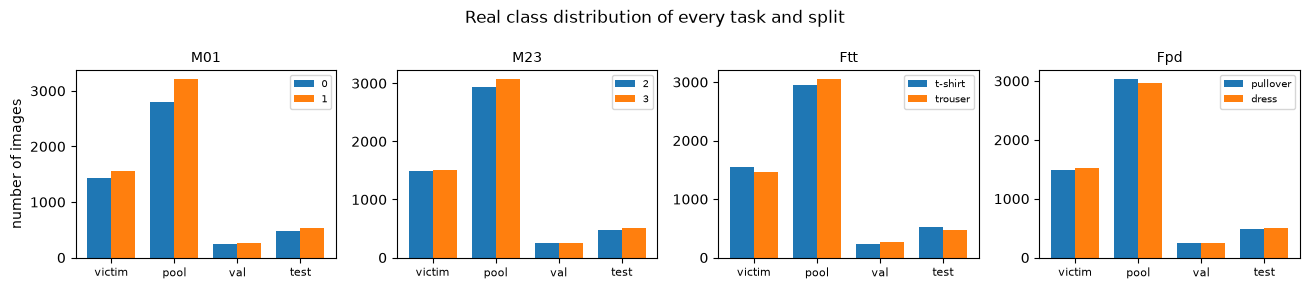

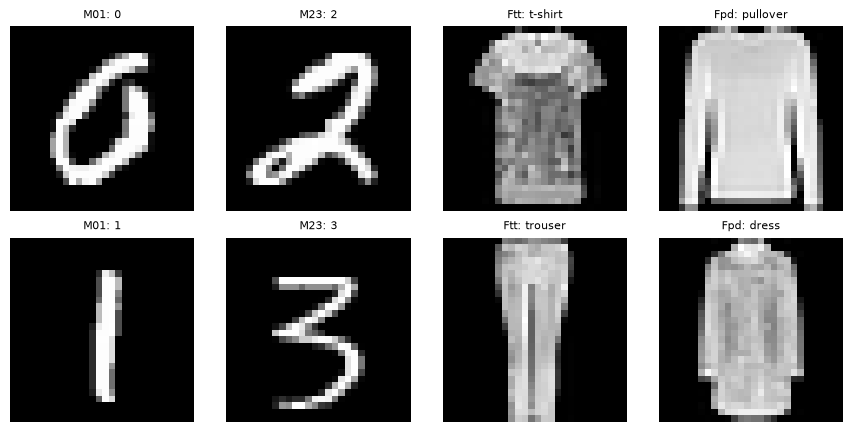

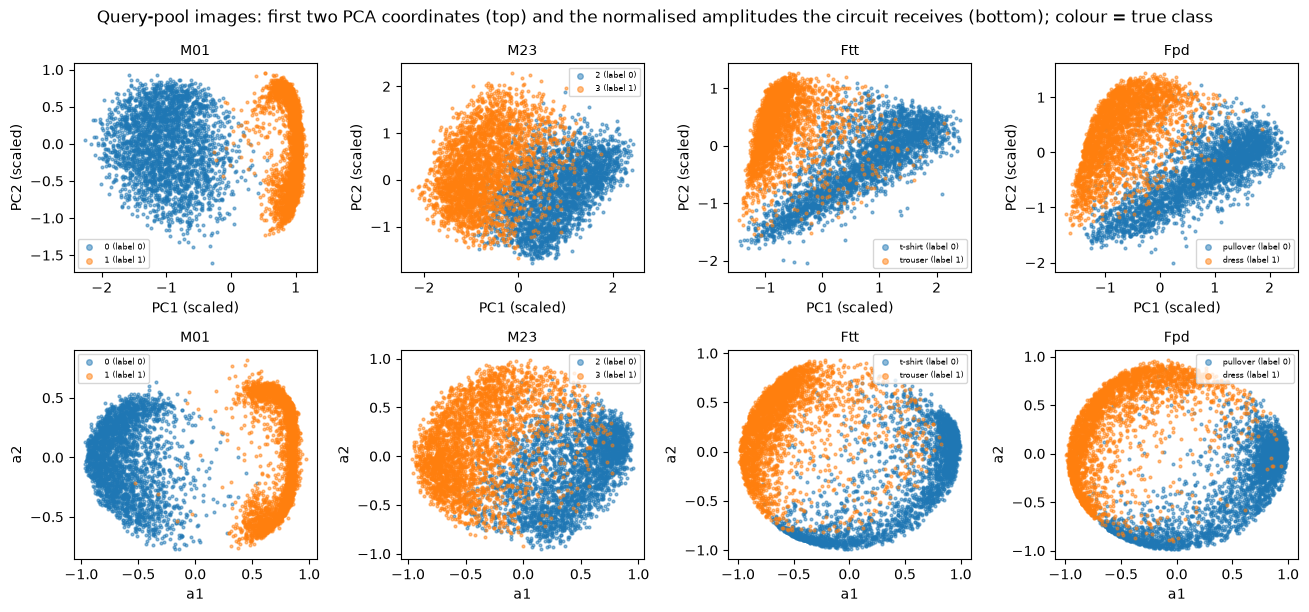

In [5]:
print("Datasets: MNIST (ylecun/mnist) and Fashion-MNIST (zalando-datasets/fashion_mnist), 28x28 grey-scale images, original label values 0..9")
rows = []
for t in TASKS:
    d = TD[t]; ds, a, b = TASK_DEF[t]
    for split, y in [("victim train", d["y_v"]), ("attacker query pool", d["y_q"]), ("validation", d["y_val"]), ("test", d["y_te"])]:
        rows.append(dict(task=t, split=split, n=len(y), classes=f"0 = {class_names(t)[0]} (orig. label {a}), 1 = {class_names(t)[1]} (orig. label {b})",
                         n_class0=int((y == 0).sum()), n_class1=int((y == 1).sum())))
    rows.append(dict(task=t, split="out-of-domain (CloudLeak)", n=len(d["y_ood"]), classes="original labels " + str(sorted(set(d["y_ood"].tolist()))), n_class0=np.nan, n_class1=np.nan))
print(pd.DataFrame(rows).astype({"n_class0": "Int64", "n_class1": "Int64"}).to_string(index=False))
d0 = TD[TASKS[0]]
print(f"\nshapes for {TASKS[0]}: images {d0['img_q'].shape} (uint8, 28x28) -> PCA features {d0['Z_q'].shape} -> amplitude vectors {d0['A_q'].shape} (8 PCA numbers + 8 zeros = 16 amplitudes = 4 qubits)")
print("feature names:", [f"PC{i + 1}" for i in range(N_PCA)], "(+ 8 zero-padded amplitudes a9..a16)")
print("PCA: explained variance ratio of PC1..PC8 for", TASKS[0], np.round(d0["pca"].explained_variance_ratio_, 3))

# --- class distribution (bar chart of the real classes in every split) ---
fig, ax = plt.subplots(1, len(TASKS), figsize=(3.3 * len(TASKS), 2.9), sharey=False, squeeze=False); ax = ax[0]
for i, t in enumerate(TASKS):
    d = TD[t]; splits = [("victim", d["y_v"]), ("pool", d["y_q"]), ("val", d["y_val"]), ("test", d["y_te"])]
    w = 0.38
    for k, c in enumerate([0, 1]):
        ax[i].bar(np.arange(4) + (k - 0.5) * w, [int((y == c).sum()) for _, y in splits], w, label=class_names(t)[c])
    ax[i].set_xticks(range(4)); ax[i].set_xticklabels([s for s, _ in splits], fontsize=8); ax[i].set_title(t, fontsize=10); ax[i].legend(fontsize=7)
ax[0].set_ylabel("number of images")
plt.suptitle("Real class distribution of every task and split"); plt.tight_layout(); plt.show()

# --- example images ---
fig, ax = plt.subplots(2, len(TASKS), figsize=(2.2 * len(TASKS), 4.4), squeeze=False)
for j, t in enumerate(TASKS):
    for r in (0, 1):
        k = int(np.where(TD[t]["y_te"] == r)[0][0]); ax[r, j].imshow(TD[t]["img_te"][k], cmap="gray"); ax[r, j].axis("off")
        ax[r, j].set_title(f"{t}: {class_names(t)[r]}", fontsize=8)
plt.tight_layout(); plt.show()

# --- 2-D scatter of real observations coloured by ground-truth class ---
fig, ax = plt.subplots(2, len(TASKS), figsize=(3.3 * len(TASKS), 6.2), squeeze=False)
for j, t in enumerate(TASKS):
    d = TD[t]
    for r, (Zq, ttl) in enumerate([(d["Z_q"][:, :2], "PCA coordinates (fitted on the victim's training split)"), (d["A_q"][:, :2], "amplitudes a1, a2 sent to the circuit (L2-normalised)")]):
        for c, col in [(0, "tab:blue"), (1, "tab:orange")]:
            m = d["y_q"] == c; ax[r, j].scatter(Zq[m, 0], Zq[m, 1], s=4, alpha=0.5, c=col, label=f"{class_names(t)[c]} (label {c})")
        ax[r, j].set_title(f"{t}", fontsize=10); ax[r, j].legend(fontsize=6, markerscale=2)
    ax[0, j].set_xlabel("PC1 (scaled)"); ax[0, j].set_ylabel("PC2 (scaled)"); ax[1, j].set_xlabel("a1"); ax[1, j].set_ylabel("a2")
plt.suptitle("Query-pool images: first two PCA coordinates (top) and the normalised amplitudes the circuit receives (bottom); colour = true class"); plt.tight_layout(); plt.show()


## 2. The quantum circuits: PyTorch for training, Qiskit for the cloud

Training a quantum circuit on a classical computer needs gradients, and Qiskit's primitives are far too slow for thousands of mini-batches. So the *trainable* circuits (victim and clones) are
simulated exactly with PyTorch (state-vector arithmetic with automatic differentiation) and the *cloud* that answers the attacker's queries is simulated with Qiskit Aer. To be sure that the two
describe the same circuit, the check at the end of this section compares them numerically.

**Circuit of the victim and of the clones L1, L2, L3.** `amplitude encoding -> L x [ RZ(a) RY(b) RZ(c) on every qubit, then CRX(theta) on (0,1), (1,2), (2,3), (3,0) ] -> <Z> on every qubit`, with `L = 2` for the victim and
`L = 1, 2, 3` for the clones L1, L2, L3. The ansatzes **A1** (fixed CNOT ring instead of CRX) and **A2** (RY only, with CRX ring) complete the "QNN zoo". The measurement layer turns the four `<Z_q>` into two class scores.
The class `BQNN` evaluates and trains *K independent circuits at once* (a batched matrix product of 16x16 unitaries), so that all victims, all ensemble members and all grid points of the experiment train together.

In [6]:
# ---------- gates (PyTorch, complex128) ----------
# Three circuit families (paper Sec. VI, "QNN zoo"):
#   "L"  : per layer RZ(a) RY(b) RZ(c) on every qubit, then CRX(theta) on the ring 0-1-2-3-0   (the victim's VQC; L1/L2/L3 = 1/2/3 layers)
#   "A1" : per block 12 one-qubit gates (RZ RY RZ on every qubit) and 4 FIXED CNOTs on the ring     (after Chen et al. [1]; CHOICE of the exact gate list)
#   "A2" : per block 4 one-qubit gates (RY on every qubit) and 4 parameterised CRX gates on the ring (after Chu et al. [2]; CHOICE of the exact gate list)
ANSATZ_MASK = {"L": torch.tensor([1., 1., 1., 1.], dtype=torch.float64), "A1": torch.tensor([1., 1., 1., 0.], dtype=torch.float64), "A2": torch.tensor([0., 1., 0., 1.], dtype=torch.float64)}

def rot_mats(abc):
    """Fused RZ(c) RY(b) RZ(a) for every row of abc (..., 3) -> (..., 2, 2) complex."""
    a, b, c = abc[..., 0], abc[..., 1], abc[..., 2]
    cb, sb = torch.cos(b / 2), torch.sin(b / 2)
    e = lambda x: torch.polar(torch.ones_like(x), x)
    return torch.stack([torch.stack([cb * e(-(a + c) / 2), -sb * e((a - c) / 2)], -1),
                        torch.stack([sb * e((c - a) / 2),  cb * e((a + c) / 2)], -1)], -2)

def crx_mat(theta):
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    rx = torch.stack([torch.stack([c + 0j, -1j * s], -1), torch.stack([-1j * s, c + 0j], -1)], -2)
    return torch.block_diag(torch.eye(2, dtype=rx.dtype), rx)

CX_MAT = torch.tensor([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=torch.complex128)

def amp_encode(x, n):
    """Amplitude encoding: real vectors (B, 2^n) -> normalised state tensor (B,2,...,2) whose axis q+1 is qubit q
    (Qiskit little endian: basis index = sum_q b_q 2^q)."""
    x = x / (x.norm(dim=1, keepdim=True) + 1e-12)
    return x.to(torch.complex128).reshape((-1,) + (2,) * n).permute(0, *range(n, 0, -1))

def apply_1q(psi, U, q):
    return torch.movedim(torch.movedim(psi, q + 1, -1) @ U.T, -1, q + 1)

def apply_2q(psi, M, q0, q1):
    psi = torch.movedim(psi, [q0 + 1, q1 + 1], [-2, -1]); shp = psi.shape
    psi = (psi.reshape(*shp[:-2], 4) @ M.T).reshape(shp)
    return torch.movedim(psi, [-2, -1], [q0 + 1, q1 + 1])

def vqc_apply(psi, params, n, ansatz="L"):
    """Gate-by-gate version. params: (L, n, 4) = per layer and qubit: (a, b, c) of RZ RY RZ and the angle of the CRX (q -> q+1 mod n)."""
    params = params * ANSATZ_MASK[ansatz]
    for l in range(params.shape[0]):
        U = rot_mats(params[l, :, :3]).to(psi.dtype)
        for q in range(n): psi = apply_1q(psi, U[q], q)
        for q in range(n): psi = apply_2q(psi, (CX_MAT if ansatz == "A1" else crx_mat(params[l, q, 3])).to(psi.dtype), q, (q + 1) % n)
    return psi

_ZS = {}
def z_expvals(psi, n):
    """<Z_q> for every qubit from a flat or tensor state (qubit 0 = most significant bit of the flat index)."""
    if n not in _ZS:
        _ZS[n] = torch.tensor([[1 - 2 * ((k >> (n - 1 - q)) & 1) for q in range(n)] for k in range(2 ** n)], dtype=torch.float64)
    return (psi.real ** 2 + psi.imag ** 2).reshape(psi.shape[0], -1).double() @ _ZS[n]

# ---------- K small circuits at once via dense unitaries ----------
_RING = {}
def ring_constants(n):
    """Constant matrices D0, D1, D2 with CRX(theta) = D0 + cos(theta/2) D1 - i sin(theta/2) D2 for control q, target (q+1) mod n.
    (D0 + D2 is the CNOT with the same control and target.)"""
    if n in _RING: return _RING[n]
    I2 = torch.eye(2, dtype=torch.complex128); P0 = torch.diag(torch.tensor([1, 0], dtype=torch.complex128))
    P1 = torch.diag(torch.tensor([0, 1], dtype=torch.complex128)); X = torch.tensor([[0, 1], [1, 0]], dtype=torch.complex128)
    def kron_all(ops):
        out = ops[0]
        for o in ops[1:]: out = torch.kron(out, o)
        return out
    D = []
    for c in range(n):
        t = (c + 1) % n
        def build(opc, opt):
            ops = [I2] * n; ops[c] = opc; ops[t] = opt
            return kron_all(ops)
        D.append(torch.stack([build(P0, I2), build(P1, I2), build(P1, X)]))
    _RING[n] = torch.stack(D)
    return _RING[n]

def vqc_unitary_b(params, n, ansatz="L"):
    """params (K, L, n, 4) -> (K, 2^n, 2^n): the unitaries of K circuits at once (qubit 0 = most significant bit)."""
    D = ring_constants(n); K = params.shape[0]; U = None
    params = params * ANSATZ_MASK[ansatz]                                      # parameters that the ansatz does not use are switched off
    for l in range(params.shape[1]):
        R = rot_mats(params[:, l, :, :3])                                      # (K,n,2,2)
        Kr = R[:, 0]
        for q in range(1, n):
            d = Kr.shape[-1]
            Kr = torch.einsum("kab,kcd->kacbd", Kr, R[:, q]).reshape(K, d * 2, d * 2)
        th = params[:, l, :, 3]
        if ansatz == "A1":
            coef = torch.tensor([1, 0, 1], dtype=torch.complex128).expand(K, n, 3)           # CNOT = D0 + D2
        else:
            coef = torch.stack([torch.ones_like(th) + 0j, torch.cos(th / 2) + 0j, -1j * torch.sin(th / 2)], -1)
        ring = torch.einsum("kqc,qcij->kqij", coef, D)
        Ul = Kr
        for q in range(n): Ul = ring[:, q] @ Ul
        U = Ul if U is None else Ul @ U
    return U

def _rev_index(n):
    return torch.tensor([int(format(j, f"0{n}b")[::-1], 2) for j in range(2 ** n)])

class BQNN(nn.Module):
    """K independent QNNs (amplitude encoding -> L VQC layers -> <Z> on every qubit), evaluated and trained together.
    Adam acts element-wise, so this is identical to training K separate models; it is just much faster in PyTorch."""
    def __init__(self, K, n, layers, seeds, ansatz="L"):
        super().__init__()
        self.n, self.L, self.K, self.ansatz = n, layers, K, ansatz
        p = [(torch.rand(layers, n, 4, generator=torch.Generator().manual_seed(int(s)), dtype=torch.float64) * 2 - 1) * math.pi for s in seeds]
        self.params = nn.Parameter(torch.stack(p)); self.rev = _rev_index(n)
    def forward(self, x):                                                      # x: (K, B, 2^n) -> (K, B, n)
        x = x / (x.norm(dim=-1, keepdim=True) + 1e-12)
        psi = torch.einsum("kbi,kji->kbj", x[..., self.rev].to(torch.complex128), vqc_unitary_b(self.params, self.n, self.ansatz))
        return z_expvals(psi.reshape(-1, 2 ** self.n), self.n).reshape(x.shape[0], x.shape[1], self.n)

def head(z):
    """Measurement layer of victim and clones: <Z> of qubits {0,1} summed -> class-0 score, qubits {2,3} -> class-1 score."""
    return z.reshape(*z.shape[:-1], 2, -1).sum(-1)

def n_params(n, L, ansatz="L"):
    """(single-qubit-gate parameters, two-qubit-gate parameters) that the ansatz really uses."""
    return {"L": (3 * n * L, n * L), "A1": (3 * n * L, 0), "A2": (n * L, n * L)}[ansatz]
print("trainable parameters: L2 (victim) 1QG %d + 2QG %d | L1 %d | L3 %d | A1 (2 blocks) %d | A2 (2 blocks) %d" %
      (*n_params(4, 2), sum(n_params(4, 1)), sum(n_params(4, 3)), sum(n_params(4, 2, "A1")), sum(n_params(4, 2, "A2"))))


trainable parameters: L2 (victim) 1QG 24 + 2QG 8 | L1 16 | L3 48 | A1 (2 blocks) 24 | A2 (2 blocks) 16


### 2b. Check: the PyTorch circuits are the same circuits as the Qiskit ones

`var_circuit` builds the variational part of every architecture in Qiskit. We compare `<Z_q>` computed by Qiskit's exact `Statevector` with the PyTorch value for random parameters and random inputs,
for the dense-unitary path used in training and for the gate-by-gate path, for each of the architectures L1, L2, L3, A1 and A2.

In [7]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, SparsePauliOp

def var_circuit(params, n=N_QUBITS, ansatz="L"):
    """Qiskit version of vqc_apply. 'L': per layer RZ(a) RY(b) RZ(c) on each qubit, then the CRX ring (q -> q+1 mod n);
    'A1': the same rotations, then a ring of CNOTs; 'A2': RY(b) only, then the CRX ring."""
    qc = QuantumCircuit(n)
    for l in range(params.shape[0]):
        for q in range(n):
            a, b, c = params[l, q, :3]
            if ansatz == "A2": qc.ry(float(b), q)
            else: qc.rz(float(a), q); qc.ry(float(b), q); qc.rz(float(c), q)
        for q in range(n):
            if ansatz == "A1": qc.cx(q, (q + 1) % n)
            else: qc.crx(float(params[l, q, 3]), q, (q + 1) % n)
    return qc

def qiskit_z(x, params, n=N_QUBITS, ansatz="L"):
    """<Z_q> of the ideal circuit |x> -> VQC, computed by Qiskit's exact Statevector."""
    qc = QuantumCircuit(n); qc.initialize(x / np.linalg.norm(x), range(n)); qc.compose(var_circuit(params, n, ansatz), inplace=True)
    sv = Statevector(qc)
    return np.array([sv.expectation_value(SparsePauliOp("I" * (n - 1 - q) + "Z" + "I" * q)).real for q in range(n)])

rg = np.random.default_rng(SEED)
x4 = torch.tensor(amp_vector(rg.normal(size=(3, N_PCA))))
for ans, Lx in [("L", 2), ("L", 1), ("L", 3), ("A1", 2), ("A2", 2)]:
    bm = BQNN(1, 4, Lx, [7], ans); par = bm.params[0].detach().numpy()
    z_dense = bm(x4[None])[0].detach().numpy()
    z_state = z_expvals(vqc_apply(amp_encode(x4, 4), bm.params[0], 4, ans), 4).detach().numpy()
    z_q = np.array([qiskit_z(x4[i].numpy(), par, 4, ans) for i in range(3)])
    err_dense, err_state = np.abs(z_q - z_dense).max(), np.abs(z_q - z_state).max()
    print(f"ansatz {ans}, {Lx} layer(s): max |Qiskit - PyTorch| of <Z>:  dense-unitary path {err_dense:.1e} | gate-by-gate path {err_state:.1e}")
    assert err_dense < 1e-8 and err_state < 1e-8
print("The PyTorch circuits (used to train and to evaluate the clones) and the Qiskit circuits (sent to the simulated cloud) agree for every architecture.")


ansatz L, 2 layer(s): max |Qiskit - PyTorch| of <Z>:  dense-unitary path 7.5e-13 | gate-by-gate path 7.5e-13
ansatz L, 1 layer(s): max |Qiskit - PyTorch| of <Z>:  dense-unitary path 1.3e-12 | gate-by-gate path 1.3e-12


ansatz L, 3 layer(s): max |Qiskit - PyTorch| of <Z>:  dense-unitary path 9.3e-13 | gate-by-gate path 9.3e-13


ansatz A1, 2 layer(s): max |Qiskit - PyTorch| of <Z>:  dense-unitary path 7.6e-13 | gate-by-gate path 7.6e-13
ansatz A2, 2 layer(s): max |Qiskit - PyTorch| of <Z>:  dense-unitary path 1.4e-12 | gate-by-gate path 1.4e-12
The PyTorch circuits (used to train and to evaluate the clones) and the Qiskit circuits (sent to the simulated cloud) agree for every architecture.


### 2c. Training routine

`fit_specs` trains many independent clones at once. Each clone is described by the queried data it uses, the sample indices (a bootstrap sample for a committee member), the loss (NLL or Huber), the architecture and its
initial parameters. Clones with the same shape train in one batched run; Adam acts element-wise, so this equals training them separately. `sample_loss` implements the two losses: NLL is the cross-entropy between the clone's softmax
and the probability vector returned by the cloud; Huber is Eq. (1) applied to the difference of the two probability vectors.

In [8]:
DELTA = 0.1          # Huber delta; replaced by the value chosen on the validation split in Section 6a

def sample_loss(z, y, huber, delta):
    """z (K,B,2) = output of the measurement layer, y (K,B,2) = probability vector returned by the cloud, huber (K,) bool -> loss per sample (K,B).
    NLL  : cross-entropy of the clone's softmax against the returned probability vector (= negative log-likelihood for one-hot labels).
    Huber: the generalised Huber loss of the paper, Eq. (1), applied to the difference of the clone's probability vector and the returned one,
           summed over the two classes (quadratic for |a| <= delta, linear beyond)."""
    l_nll = -(y * F.log_softmax(z, -1)).sum(-1)
    l_hub = F.huber_loss(F.softmax(z, -1), y, reduction="none", delta=delta).sum(-1)
    return torch.where(huber[:, None], l_hub, l_nll)

def fit_specs(specs, bank, lr, train_seed, delta=None, bs=None):
    """Train many independent clones at once. spec = dict(bank=key, idx=int array of training samples (a bootstrap sample for ensemble members),
    huber=bool, layers=int, ansatz=str, seed=int (initial parameters), epochs=int, init=None or parameter array (warm start)).
    bank[key] = (X (n,16) amplitude vectors, Y (n,2) returned probability vectors). Models with the same (ansatz, layers, n_samples, epochs)
    are trained together in one batched run. Returns the trained parameters, one array (L,4,4) per spec."""
    delta = DELTA if delta is None else delta; bs = CLONE_BS if bs is None else bs
    groups = {}
    for i, s in enumerate(specs): groups.setdefault((s["ansatz"], s["layers"], len(s["idx"]), s["epochs"]), []).append(i)
    out = [None] * len(specs)
    for (ans, L, n, E), ids in groups.items():
        K = len(ids); keys = sorted({specs[i]["bank"] for i in ids}); kpos = {k: j for j, k in enumerate(keys)}
        Nm = max(len(bank[k][0]) for k in keys)
        Xb = torch.zeros(len(keys), Nm, 2 ** N_QUBITS, dtype=torch.float64); Yb = torch.zeros(len(keys), Nm, 2, dtype=torch.float64)
        for k in keys:
            Xb[kpos[k], :len(bank[k][0])] = torch.tensor(bank[k][0]); Yb[kpos[k], :len(bank[k][1])] = torch.tensor(bank[k][1])
        src = torch.tensor([kpos[specs[i]["bank"]] for i in ids])[:, None]
        idx = torch.tensor(np.stack([specs[i]["idx"] for i in ids]))
        hub = torch.tensor([bool(specs[i]["huber"]) for i in ids])
        model = BQNN(K, N_QUBITS, L, [specs[i]["seed"] for i in ids], ans)
        for j, i in enumerate(ids):
            if specs[i].get("init") is not None: model.params.data[j] = torch.tensor(specs[i]["init"])
        g = torch.Generator().manual_seed(int(train_seed) * 7919 + E * 31 + n)
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=CLONE_WD)
        for ep in range(E):
            order = torch.gather(idx, 1, torch.argsort(torch.rand(K, n, generator=g), dim=1))
            for s0 in range(0, n, bs):
                ib = order[:, s0:s0 + bs]
                z = head(model(Xb[src, ib]))
                l = sample_loss(z, Yb[src, ib], hub, delta).mean(1).sum()
                opt.zero_grad(); l.backward(); opt.step()
        for j, i in enumerate(ids): out[i] = model.params[j].detach().numpy().copy()
    return out

def logits_of(params, ansatz, X):
    """Output of the measurement layer of ONE trained clone for amplitude vectors X (m,16) -> (m,2) array."""
    m = BQNN(1, N_QUBITS, params.shape[0], [0], ansatz); m.params.data = torch.tensor(params)[None].clone()
    with torch.no_grad(): return head(m(torch.tensor(X)[None]))[0].numpy()

def probs_of_raw(raw):
    """Raw <Z> output of the service (m,4) -> probability vector over the two classes (softmax of the measurement layer, as the QNN does)."""
    return F.softmax(head(torch.as_tensor(raw)), -1).numpy()


## 3. The victim QNNs (trained noise-free by their owner)

Each task gets its own victim: 4 qubits, amplitude encoding of the 8 PCA numbers, two VQC layers, measurement layer, softmax. Training follows the paper (NLL, Adam, weight decay 1e-4, batch size 32;
learning rate 1e-3 and 100 epochs in the full run). All victims train in one batched run. The accuracy is that of an ideal (noise-free) simulator, the paper's "Ideal" victim.

In [9]:
t0 = time.time()
vbank = {t: (TD[t]["A_v"], np.eye(2)[TD[t]["y_v"]]) for t in TASKS}                       # one-hot labels: NLL = ordinary cross-entropy
vspecs = [dict(bank=t, idx=np.arange(N_VICTIM), huber=False, layers=N_LAYERS, ansatz="L", seed=SEED + 7 * i, epochs=VICTIM_EPOCHS, init=None) for i, t in enumerate(TASKS)]
vparams = fit_specs(vspecs, vbank, VICTIM_LR, SEED, bs=VICTIM_BS)                         # NLL, Adam, weight decay 1e-4, batch 32 (paper)
VIC = {}
for t, par in zip(TASKS, vparams):
    d = TD[t]; lt = logits_of(par, "L", d["A_te"])
    VIC[t] = dict(params=par, ideal_pred=lt.argmax(1), ideal_acc=float((lt.argmax(1) == d["y_te"]).mean()),
                  ideal_P_pool=F.softmax(torch.tensor(logits_of(par, "L", d["A_q"])), -1).numpy(),            # noise-free answers to the query pool (the attacker never sees them)
                  ideal_P_ood=F.softmax(torch.tensor(logits_of(par, "L", d["A_ood"])), -1).numpy())
print(f"trained {len(TASKS)} victims in {time.time() - t0:.0f} s (epochs={VICTIM_EPOCHS}, lr={VICTIM_LR}, batch={VICTIM_BS})")
print(pd.Series({t: round(VIC[t]["ideal_acc"] * 100, 2) for t in TASKS}, name="ideal (noise-free) victim test accuracy (%)").to_frame().T.to_string())


trained 4 victims in 392 s (epochs=100, lr=0.001, batch=32)
                                              M01   M23   Ftt   Fpd
ideal (noise-free) victim test accuracy (%)  94.6  81.9  83.1  79.8


## 4. The simulated QNN-as-a-Service: a noisy cloud whose noise drifts during the day

The paper queries IBM_Auckland in three rounds over a day and stresses that NISQ noise changes over time. We have no hardware, so the cloud is a **Qiskit Aer density-matrix simulation** with a noise model whose parameters
change smoothly over 24 hours (`DeviceDrift`: a few sinusoids with random periods and phases per noise component):

* depolarising error on RY (single-qubit) and CX (two-qubit) gates; RZ is a virtual gate on IBM machines and is noise free,
* amplitude damping (T1-like) after the gates and after state preparation, which pushes qubits towards |0>,
* asymmetric read-out error `P(1|0) < P(0|1)` (SPAM, Table I of the paper),
* a small coherent RY over-rotation per qubit that wanders over the day (the paper cites control imperfections and crosstalk).

State preparation is ideal (`set_statevector`), followed by one noisy `id` gate per qubit that represents the deep circuit into which amplitude encoding is compiled on real hardware.
The service returns, as in the paper, the raw output estimated from `SHOTS` measurement shots, from which the client computes the probability vector. A single global scale **`NOISE_LEVEL`** multiplies all noise strengths; it is the only fitted number of the notebook (Section 4b).
Every component has a static part (for example a fixed over-rotation per qubit, the same all day: such errors make the same images wrong in every round) and a time-dependent part of relative size `DRIFT`.

**Speed trick, and why it is exact.** The noisy circuit is a linear map of the density matrix, hence for a real input vector `x` the probability of outcome `k` is `p_k(x) = x^T S_k x` for 16 fixed symmetric matrices. They are read off from a few dozen Aer runs per
(task, round) with the inputs |i> and (|i> + |j>)/sqrt2; because every input has only 8 non-zero amplitudes (the 8 PCA numbers), only the 8 x 8 block of each matrix is needed, i.e. 36 Aer runs. Every query of that round is then a matrix product, and the shots are sampled from `p`. The last lines of the next cell compare this with direct Aer runs that include measurement and read-out error.

In [10]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (NoiseModel, depolarizing_error, ReadoutError, amplitude_damping_error, coherent_unitary_error)
from qiskit_aer.library import SetStatevector, SaveProbabilities  # noqa: F401  (registers QuantumCircuit.set_statevector / save_probabilities)
from qiskit.quantum_info import Operator
from qiskit.circuit.library import RYGate

CLOUD_BASIS = ["rx", "ry", "rz", "cx", "id"]
SGN = np.array([[1 - 2 * ((k >> q) & 1) for q in range(N_QUBITS)] for k in range(2 ** N_QUBITS)])     # eigenvalue of Z_q on basis state k

class DeviceDrift:
    """One simulated day of a device. Besides a *static* part (a fixed coherent error per qubit, the same all day) every noise
    component drifts smoothly: a few sinusoids (periods 2 h ... 24 h, random phases). value(h, k) is roughly in [-1, 1].
    One seed = one simulated day (different static offsets and different drift)."""
    def __init__(self, seed, n_series=16, n_waves=4):
        g = np.random.default_rng(seed)
        self.per = g.uniform(2.0, 24.0, (n_series, n_waves)); self.ph = g.uniform(0, 2 * np.pi, (n_series, n_waves))
        self.amp = g.uniform(0.3, 1.0, (n_series, n_waves)); self.amp /= self.amp.sum(1, keepdims=True)
        self.static = g.uniform(0.5, 1.0, 8) * g.choice([-1.0, 1.0], 8)
    def value(self, h, k):
        return float((self.amp[k] * np.sin(2 * np.pi * h / self.per[k] + self.ph[k])).sum())

def noise_at(h, day, level, n=N_QUBITS):
    """Noise parameters of the simulated device at hour h of `day`. CHOICE: base values are typical NISQ orders of magnitude
    times `level`; every component drifts with time by +-DRIFT (relative)."""
    d = lambda k: day.value(h, k)
    s = 1 + DRIFT * d(0)                                                     # overall multiplier of gate noise
    return dict(p1=0.002 * level * s, p2=0.02 * level * s, gamma=0.01 * level * s,
                p_ro01=0.02 * level * (1 + DRIFT * d(1)), p_ro10=0.04 * level * (1 + DRIFT * d(2)), p_enc=0.03 * level * s,
                delta=[0.12 * level * (day.static[q] + DRIFT * d(3 + q)) for q in range(n)])   # coherent RY over-rotation per qubit (rad)

def make_noise_model(nz, n=N_QUBITS, readout=True):
    nm = NoiseModel(basis_gates=CLOUD_BASIS + ["set_statevector"])
    ad1 = amplitude_damping_error(min(1.0, nz["gamma"] * 0.5))
    for q in range(n):
        coh = coherent_unitary_error(Operator(RYGate(nz["delta"][q])))
        nm.add_quantum_error(coh.compose(depolarizing_error(nz["p1"], 1)).compose(ad1), ["ry"], [q])
        nm.add_quantum_error(depolarizing_error(nz["p1"], 1), ["rx"], [q])
    ad2 = amplitude_damping_error(min(1.0, nz["gamma"]))
    nm.add_all_qubit_quantum_error(depolarizing_error(nz["p2"], 2).compose(ad2.tensor(ad2)), ["cx"])
    nm.add_all_qubit_quantum_error(depolarizing_error(nz["p_enc"], 1).compose(amplitude_damping_error(min(1.0, nz["gamma"] * 2))), ["id"])
    if readout:
        nm.add_all_qubit_readout_error(ReadoutError([[1 - nz["p_ro01"], nz["p_ro01"]], [nz["p_ro10"], 1 - nz["p_ro10"]]]))
    return nm

def cloud_circuit(amp, var_t, n=N_QUBITS, measure=True, save=False):
    """The circuit the QNN-as-a-Service executes for one query: amplitude encoding (one noisy `id` per qubit stands for the compiled
    encoding circuit), the victim's VQC, and the measurement."""
    qc = QuantumCircuit(n, n if measure else 0); qc.set_statevector(amp)
    for q in range(n): qc.id(q)
    qc.compose(var_t, inplace=True)
    if measure: qc.measure(range(n), range(n))
    if save: qc.save_probabilities()
    return qc

def fit_cloud_channel(params, nz, n=N_QUBITS):
    """Qiskit-Aer density-matrix simulation of the noisy cloud, condensed into 16 symmetric matrices S_k.
    For a real input vector x (unit norm) the probability of measuring basis state k is exactly p_k(x) = x^T S_k x, because the noisy
    circuit is a linear map of the density matrix |x><x|. Every input has only 8 non-zero amplitudes (the 8 PCA numbers), so an 8x8 block of
    S_k is enough: it is read off from the 8 basis states |i> and the 28 states (|i>+|j>)/sqrt2 (36 Aer runs); the classical read-out error is
    applied afterwards. This gives the exact noisy output distribution of any input in one matrix product instead of one Aer run per query."""
    dim = 2 ** n; din = N_PCA; var_t = transpile(var_circuit(params, n), basis_gates=CLOUD_BASIS, optimization_level=0)
    backend = AerSimulator(method="density_matrix", noise_model=make_noise_model(nz, n, readout=False))
    pairs = [(i, j) for i in range(din) for j in range(i + 1, din)]            # inputs have only 8 non-zero amplitudes (8 PCA numbers): an 8x8 block of S_k is enough
    vecs = []
    for i in range(din): v = np.zeros(dim, complex); v[i] = 1; vecs.append(v)
    for i, j in pairs: v = np.zeros(dim, complex); v[i] = v[j] = 1 / np.sqrt(2); vecs.append(v)
    res = backend.run([cloud_circuit(v, var_t, n, measure=False, save=True) for v in vecs]).result()
    P = np.array([res.data(k)["probabilities"] for k in range(len(vecs))])                      # (136, 16): outcome distribution before read-out error
    C = np.array([[1 - nz["p_ro01"], nz["p_ro10"]], [nz["p_ro01"], 1 - nz["p_ro10"]]])           # confusion matrix of one qubit (rows: measured, columns: true)
    R = C
    for _ in range(n - 1): R = np.kron(R, C)
    P = P @ R.T                                                                                  # apply the read-out error
    S = np.zeros((dim, dim, dim))                                                                # S[i, j, k] (zero outside the 8x8 block)
    for i in range(din): S[i, i] = P[i]
    for m, (i, j) in enumerate(pairs):
        S[i, j] = S[j, i] = P[din + m] - 0.5 * (P[i] + P[j])
    return S.transpose(2, 0, 1)                                                                  # (k, i, j)

def cloud_answer(amps, S, shots, g):
    """What the service returns for a batch of queries: the raw output <Z_q> estimated from `shots` measurement shots, shape (N, 4),
    together with the exact noisy outcome distribution (not visible to an attacker, used for checks only)."""
    assert np.abs(np.asarray(amps)[:, N_PCA:]).max() < 1e-12, "the condensed channel is only valid for inputs with 8 non-zero amplitudes"
    x = amps / (np.linalg.norm(amps, axis=1, keepdims=True) + 1e-12)
    p = np.einsum("ni,kij,nj->nk", x, S, x); p = np.clip(p, 0, None); p /= p.sum(1, keepdims=True)
    counts = g.multinomial(shots, p)
    return counts @ SGN / shots, p @ SGN

def to_probs(raw):
    """Raw <Z> output of the service -> probability vector over the two classes (softmax of the measurement layer, as the QNN does)."""
    return F.softmax(head(torch.tensor(raw)), -1).numpy()

# ---- check 1: the condensed channel reproduces a direct Aer run with measurement and read-out error ----
day_chk = DeviceDrift(0); nz_chk = noise_at(6.0, day_chk, 2.0)
par_chk = VIC[TASKS[0]]["params"]; S_chk = fit_cloud_channel(par_chk, nz_chk)
imgs_chk = TD[TASKS[0]]["A_te"][:12]
var_chk = transpile(var_circuit(par_chk), basis_gates=CLOUD_BASIS, optimization_level=0)
direct = AerSimulator(method="density_matrix", noise_model=make_noise_model(nz_chk))
res_chk = direct.run([cloud_circuit(v.astype(complex), var_chk) for v in imgs_chk], shots=40000, seed_simulator=SEED).result()
z_direct = np.array([[sum(cnt * SGN[int(key, 2), q] for key, cnt in res_chk.get_counts(i).items()) / 40000 for q in range(N_QUBITS)] for i in range(len(imgs_chk))])
_, z_exact = cloud_answer(imgs_chk, S_chk, 1000, np.random.default_rng(0))
print(f"max |<Z> direct Aer (40000 shots) - <Z> from the condensed channel| over 12 images and 4 qubits: {np.abs(z_direct - z_exact).max():.4f}  (shot noise ~0.005)")
assert np.abs(z_direct - z_exact).max() < 0.03


max |<Z> direct Aer (40000 shots) - <Z> from the condensed channel| over 12 images and 4 qubits: 0.0128  (shot noise ~0.005)


### 4a. Querying the cloud: helper functions

`cloud_labels` answers a batch of images in `M = 3` rounds (image `i` in round `i mod 3`, at the device state of hour `24 k / 3`) and returns the probability vectors the attacker sees; `channels_for` fits the three condensed channels of a task's victim for a
given simulated day; `victim_real_acc` measures the victim's accuracy on the noisy device (a diagnostic the attacker cannot see).

In [11]:
def cloud_labels(S_list, amps, g, offset=0):
    """What the QNN-as-a-Service returns for a batch of query images: image i is answered in round (i + offset) mod M by the device as it is
    at hour 24 (round) / M (paper Sec. IV-B: the queries are distributed evenly over the day). Returns the probability vectors (n,2)."""
    amps = np.asarray(amps); P = np.zeros((len(amps), 2)); rnd = (np.arange(len(amps)) + offset) % M_ROUNDS
    for k in range(M_ROUNDS):
        m = rnd == k
        if m.any():
            raw, _ = cloud_answer(amps[m], S_list[k], SHOTS, g)
            P[m] = probs_of_raw(raw)
    return P

def channels_for(task, day, level):
    """The M condensed channels of the simulated device for the victim of `task`: one per query round."""
    return [fit_cloud_channel(VIC[task]["params"], noise_at(24.0 * k / M_ROUNDS, day, level)) for k in range(M_ROUNDS)]

def victim_real_acc(task, S_list, g):
    """Accuracy of the victim on the noisy cloud: the test images are answered in the M rounds (a diagnostic the attacker cannot see)."""
    P = cloud_labels(S_list, TD[task]["A_te"], g)
    return float((P.argmax(1) == TD[task]["y_te"]).mean()), P.argmax(1)


### 4b. Fitting the one free number: the noise scale

The paper does not give the error rates of the day it measured, but Table II reports the accuracy of each victim on the ideal simulator and on IBM_Auckland: 89.55 -> 86.18, 84.22 -> 81.44, 77.02 -> 75.47 and 76.92 -> 76.05 %, an average drop of **2.14 points**.
The drop of a simulated victim depends strongly on the simulated day (static coherent offsets are drawn per day), so for every NOISE_LEVEL of CAL_LEVELS we average the drop over N_CAL_DAYS calibration days and the four tasks and choose, once, the level closest to 2.14 points.
**This fixes the average victim drop; it is a fit and not a test.** Everything else (how the drop is distributed over the tasks, every clone accuracy, every comparison between the schemes) is a prediction of the fitted simulator.

  level 0.75: mean drop 1.30 points (std over days 0.05)  [15 s]


  level 1.0: mean drop 2.19 points (std over days 0.34)  [29 s]


  level 1.25: mean drop 3.75 points (std over days 0.45)  [43 s]


  level 1.5: mean drop 5.79 points (std over days 0.76)  [56 s]


  level 1.75: mean drop 8.01 points (std over days 0.24)  [71 s]


  level 2.0: mean drop 9.79 points (std over days 0.01)  [84 s]


             drop M01  drop M23  drop Ftt  drop Fpd  mean_drop  std_over_days
NOISE_LEVEL                                                                  
0.75            -0.90      1.25      2.70      2.15       1.30           0.05
1.00            -1.10      2.20      5.70      1.95       2.19           0.34
1.25            -1.30      2.60      9.15      4.55       3.75           0.45
1.50            -1.30      4.60     14.35      5.50       5.79           0.76
1.75            -0.90      7.00     19.00      6.95       8.01           0.24
2.00             0.65      9.10     21.75      7.65       9.79           0.01

Paper (Table II): victim ideal -> real drops of 8.57 points in total over four tasks, i.e. 2.14 points per task on average
NOISE_LEVEL = 1.0: the mean accuracy drop of the victims is closest to the paper's (2.19 points)   [84 s]


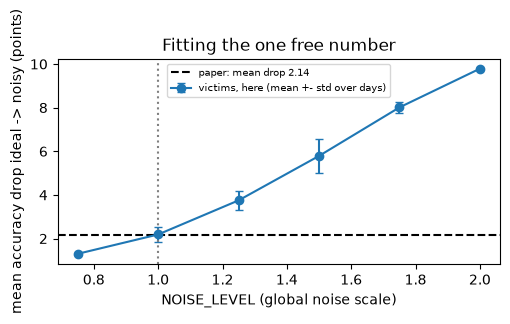

In [12]:
t0 = time.time()
# The accuracy drop of a victim depends strongly on the simulated day (the static coherent offsets are drawn per day), so the drop is averaged over N_CAL_DAYS calibration days
# (seeds 900 ... 900 + N_CAL_DAYS - 1; the experiments below use other days) and over the four tasks (paper: 3.37, 2.78, 1.55, 0.87 points, mean 2.14).
cal_rows = []
for lev in CAL_LEVELS:
    drops = np.zeros((N_CAL_DAYS, len(TASKS)))
    for dd in range(N_CAL_DAYS):
        day_c = DeviceDrift(900 + dd)
        for ti, t in enumerate(TASKS):
            a_ = victim_real_acc(t, channels_for(t, day_c, lev), np.random.default_rng(900 + dd))[0] * 100
            drops[dd, ti] = 100 * VIC[t]["ideal_acc"] - a_
    cal_rows.append(dict(NOISE_LEVEL=lev, **{f"drop {t}": drops[:, ti].mean() for ti, t in enumerate(TASKS)}, mean_drop=drops.mean(), std_over_days=drops.mean(1).std()))
    print(f"  level {lev}: mean drop {cal_rows[-1]['mean_drop']:.2f} points (std over days {cal_rows[-1]['std_over_days']:.2f})  [{time.time() - t0:.0f} s]", flush=True)
cal_df = pd.DataFrame(cal_rows).set_index("NOISE_LEVEL")
NOISE_LEVEL = float(min(CAL_LEVELS, key=lambda l: abs(cal_df.loc[l, "mean_drop"] - PAPER_MEAN_DROP)))     # CHOICE: the single fitted number
print(cal_df.round(2).to_string())
print(f"\nPaper (Table II): victim ideal -> real drops of {PAPER_MEAN_DROP * 4:.2f} points in total over four tasks, i.e. {PAPER_MEAN_DROP:.2f} points per task on average")
print(f"NOISE_LEVEL = {NOISE_LEVEL}: the mean accuracy drop of the victims is closest to the paper's ({cal_df.loc[NOISE_LEVEL, 'mean_drop']:.2f} points)   [{time.time() - t0:.0f} s]")
plt.figure(figsize=(5.2, 3)); plt.errorbar(cal_df.index, cal_df["mean_drop"], yerr=cal_df["std_over_days"], fmt="o-", capsize=3, label="victims, here (mean +- std over days)"); plt.axhline(PAPER_MEAN_DROP, color="k", ls="--", label=f"paper: mean drop {PAPER_MEAN_DROP:.2f}")
plt.axvline(NOISE_LEVEL, color="grey", ls=":"); plt.xlabel("NOISE_LEVEL (global noise scale)"); plt.ylabel("mean accuracy drop ideal -> noisy (points)"); plt.title("Fitting the one free number"); plt.legend(fontsize=7); plt.tight_layout(); plt.show()


## 5. Querying the victim: what the attacker receives

For each seed, a fresh simulated day is drawn (different static offsets and different drift). The attacker sends the whole query pool (up to 6000 images) in three rounds, plus the out-of-domain images needed by CloudLeak.
The next cell tells how wrong the stolen labels are: how often the arg-max of the returned probability vector equals the true label, equals the noise-free victim's decision, and how this differs between the rounds.

In [13]:
def build_QD(level, seeds, salt=0):
    """Query the simulated cloud with noise scale `level` on one fresh simulated day per seed: for every task the whole query pool and the out-of-domain images,
    answered in M rounds. Returns {(seed, task): {S: channels, g: random generator, vacc, vpred, real: {...}, ideal: {...}}}."""
    out = {}
    for seed in seeds:
        day = DeviceDrift(2000 + seed)                                               # a fresh simulated day per seed (not a calibration day)
        for ti, t in enumerate(TASKS):
            g = np.random.default_rng(seed * 1000 + ti + salt)
            S_list = channels_for(t, day, level); d = TD[t]
            vacc, vpred = victim_real_acc(t, S_list, g)
            out[(seed, t)] = dict(S=S_list, g=g, vacc=vacc, vpred=vpred,
                                  real=dict(P_pool=cloud_labels(S_list, d["A_q"], g), P_ood=cloud_labels(S_list, d["A_ood"], g)),
                                  ideal=dict(P_pool=VIC[t]["ideal_P_pool"], P_ood=VIC[t]["ideal_P_ood"]))
        print(f"  noise level {level}, seed {seed}: queried {len(TASKS)} tasks x ({N_POOL} + {N_OOD} images) in {M_ROUNDS} rounds   [{time.time() - t0:.0f} s]", flush=True)
    return out

t0 = time.time()
QD = build_QD(NOISE_LEVEL, SEEDS)                      # (seed, task) -> everything the cloud answered for that simulated day
sd0 = SEEDS[0]
qrows = []
for t in TASKS:
    q = QD[(sd0, t)]["real"]["P_pool"]; lab = q.argmax(1); ide = VIC[t]["ideal_P_pool"].argmax(1); yq = TD[t]["y_q"]
    rnd = np.arange(len(lab)) % M_ROUNDS
    qrows.append({"task": t, "ideal victim acc (%)": 100 * VIC[t]["ideal_acc"], "noisy victim acc (%)": 100 * np.mean([QD[(s, t)]["vacc"] for s in SEEDS]),
                  "cloud label = true label (%)": 100 * (lab == yq).mean(), "ideal label = true label (%)": 100 * (ide == yq).mean(),
                  "cloud label = ideal label (%)": 100 * (lab == ide).mean(),
                  "cloud label correct per round (%)": " / ".join(f"{100 * (lab[rnd == k] == yq[rnd == k]).mean():.1f}" for k in range(M_ROUNDS))})
print(f"Seed {sd0}: quality of what the simulated cloud returns for the query pool ({N_POOL} images; 'noisy victim acc' = mean over seeds on the test set)")
print(pd.DataFrame(qrows).set_index("task").round(1).to_string())


  noise level 1.0, seed 42: queried 4 tasks x (6000 + 512 images) in 3 rounds   [8 s]


  noise level 1.0, seed 43: queried 4 tasks x (6000 + 512 images) in 3 rounds   [16 s]


  noise level 1.0, seed 44: queried 4 tasks x (6000 + 512 images) in 3 rounds   [23 s]


Seed 42: quality of what the simulated cloud returns for the query pool (6000 images; 'noisy victim acc' = mean over seeds on the test set)
      ideal victim acc (%)  noisy victim acc (%)  cloud label = true label (%)  ideal label = true label (%)  cloud label = ideal label (%) cloud label correct per round (%)
task                                                                                                                                                                         
M01                   94.6                  94.4                          95.8                          94.8                           95.9                96.5 / 95.8 / 95.0
M23                   81.9                  78.0                          78.6                          83.0                           90.7                77.6 / 78.4 / 79.9
Ftt                   83.1                  82.0                          84.3                          85.7                           93.7                85.3 / 85

## 6. The attack schemes

`run_configs` trains and evaluates the four schemes of the paper (and two "plain" ablations) for a list of configurations: task, noise-free ("ideal") or noisy ("real") cloud, query budget, number of layers, ansatz and committee size.

* **Ens-N / Ens-H (QuantumLeak):** `N_C` bootstrap samples of `N_Q / N_C` queried images (drawn with replacement), one local QNN per sample, majority vote of the hard labels. The out-of-bag accuracy (agreement of a member with the cloud's labels on the images it never saw) is reported.
* **Single-N / Single-H (CloudLeak):** one local QNN trained on all `N_Q` answers plus the out-of-domain answers (first half of the epochs); then adversarial (FGSM) images are crafted against this clone, queried, and training continues on everything (second half). The attacker pays for `N_Q` + out-of-domain + adversarial queries.
* **plain singles:** one local QNN on the `N_Q` answers only.

`-N` uses the NLL loss, `-H` the Huber loss. Across the schemes the bootstrap samples and the initial parameters are shared (paired comparison).

In [14]:
SCHEMES = ["Single-N", "Single-H", "Ens-N", "Ens-H"]                                  # the four schemes of the paper (Fig. 4)
PLAIN = ["Single-N (plain)", "Single-H (plain)"]                                      # additional ablation: single clone WITHOUT the CloudLeak add-ons
KEEP, PREDS = {}, {}                                                                  # trained parameters / test predictions, kept for figures

def answer(seed, task, scen, X, offset=0, Q=None):
    """The service's answer (probability vectors) for amplitude vectors X: 'ideal' = noise-free simulator, 'real' = the simulated noisy cloud."""
    if scen == "ideal": return F.softmax(torch.tensor(logits_of(VIC[task]["params"], "L", X)), -1).numpy()
    q = (QD if Q is None else Q)[(seed, task)]; return cloud_labels(q["S"], X, q["g"], offset)

def craft_adversarial(params, ansatz, X):
    """CloudLeak's adversarial queries (FGSM): move every image one step of size EPS_ADV along the sign of the gradient that increases the loss of the clone's own
    predicted class, so that the new images lie near the clone's decision boundary. Only the 8 PCA coordinates are changed (the service takes 8 numbers)."""
    m = BQNN(1, N_QUBITS, params.shape[0], [0], ansatz); m.params.data = torch.tensor(params)[None].clone(); m.params.requires_grad_(False)
    x = torch.tensor(X, requires_grad=True); z = head(m(x[None]))[0]
    F.cross_entropy(z, z.argmax(1), reduction="sum").backward()
    step = x.grad.sign(); step[:, N_PCA:] = 0
    xa = x.detach() + EPS_ADV * step
    return (xa / xa.norm(dim=1, keepdim=True)).numpy()

def epochs_for(n):
    """Epochs for a clone with n training samples: CLONE_EPOCHS, but at least MIN_STEPS optimiser steps. CHOICE: the paper trains every clone for 100 epochs, which gives
    every configuration (even 1500/7 = 214 samples) hundreds of steps; with our shorter schedule small bootstrap samples would otherwise be under-trained."""
    return max(CLONE_EPOCHS, math.ceil(MIN_STEPS / math.ceil(n / CLONE_BS)))

def run_configs(configs, Q=None):
    """Train and evaluate attack configurations (all seeds together, so that many clones train in one batch).
    config = dict(seed, task, scen, nq, layers, ansatz, nc, schemes).
    * Ens-N / Ens-H (QuantumLeak): nc bootstrap samples of nq/nc images drawn with replacement from the queried data, one clone per sample, majority vote.
    * Single-N / Single-H (CloudLeak): one clone on all nq answers + out-of-domain images, then adversarial queries and a second training stage.
    * 'plain' singles: one clone on the nq answers only.   '-N' = NLL loss, '-H' = Huber loss.   Returns one row per (config, scheme)."""
    Q = QD if Q is None else Q                                                              # the queried data (default: the calibrated cloud)
    bank, specs, meta = {}, [], []
    for ci, c in enumerate(configs):
        seed, t, scen, nq = c["seed"], c["task"], c["scen"], c["nq"]; ti = TASKS.index(t); d = TD[t]; qd = Q[(seed, t)][scen]
        n_ood = max(1, round(N_OOD * nq / N_POOL))
        bank[f"{ci}|pool"] = (d["A_q"][:nq], qd["P_pool"][:nq])
        bank[f"{ci}|pool+ood"] = (np.vstack([d["A_q"][:nq], d["A_ood"][:n_ood]]), np.vstack([qd["P_pool"][:nq], qd["P_ood"][:n_ood]]))
        for sch in c["schemes"]:
            hub = "-H" in sch; base_seed = seed * 1000 + 17 * ti + 3 * c["layers"] + {"L": 0, "A1": 1, "A2": 2}[c["ansatz"]]
            if sch.startswith("Ens"):
                for mbr in range(c["nc"]):
                    rg_ = np.random.default_rng([seed, ti, int(scen == "real"), nq, c["nc"], mbr])
                    idx = rg_.integers(0, nq, nq // c["nc"])                                             # i.i.d. bootstrap sample with replacement
                    specs.append(dict(bank=f"{ci}|pool", idx=idx, huber=hub, layers=c["layers"], ansatz=c["ansatz"], seed=base_seed + 100 * mbr, epochs=epochs_for(len(idx)), init=None))
                    meta.append((ci, sch, mbr))
            elif "plain" in sch:
                specs.append(dict(bank=f"{ci}|pool", idx=np.arange(nq), huber=hub, layers=c["layers"], ansatz=c["ansatz"], seed=base_seed, epochs=epochs_for(nq), init=None)); meta.append((ci, sch, 0))
            else:
                E_tot = epochs_for(nq + n_ood + 2 * n_ood)                                               # total epochs of the two stages
                specs.append(dict(bank=f"{ci}|pool+ood", idx=np.arange(nq + n_ood), huber=hub, layers=c["layers"], ansatz=c["ansatz"], seed=base_seed, epochs=max(1, E_tot // 2), init=None)); meta.append((ci, sch, 0))
                specs[-1]["E_tot"] = E_tot
    outA = fit_specs(specs, bank, CLONE_LR, SEED)
    # ---- second stage of the CloudLeak singles: craft adversarial queries from the stage-1 clone, query the cloud, keep training ----
    specs2, idx2, nq_extra = [], [], {}
    for k, (ci, sch, mbr) in enumerate(meta):
        if sch.startswith("Single") and "plain" not in sch:
            c = configs[ci]; seed, t, scen, nq = c["seed"], c["task"], c["scen"], c["nq"]; d = TD[t]; n_ood = max(1, round(N_OOD * nq / N_POOL))
            Xadv = craft_adversarial(outA[k], c["ansatz"], d["A_q"][:n_ood]); Yadv = answer(seed, t, scen, Xadv, Q=Q)
            bx, by = bank[f"{ci}|pool+ood"]; key = f"{ci}|{sch}|full"
            bank[key] = (np.vstack([bx, Xadv]), np.vstack([by, Yadv])); nq_extra[k] = n_ood + n_ood
            s = dict(specs[k]); s.update(bank=key, idx=np.arange(len(bank[key][0])), epochs=max(1, specs[k]["E_tot"] - specs[k]["epochs"]), init=outA[k]); specs2.append(s); idx2.append(k)
    outB = fit_specs(specs2, bank, CLONE_LR, SEED + 1) if specs2 else []
    final = list(outA)
    for k, par in zip(idx2, outB): final[k] = par
    # ---- evaluate ----
    rows = []; by_cfg = {}
    for k, (ci, sch, mbr) in enumerate(meta): by_cfg.setdefault((ci, sch), []).append(k)
    for (ci, sch), ks in by_cfg.items():
        c = configs[ci]; seed, t, scen, nq = c["seed"], c["task"], c["scen"], c["nq"]; d = TD[t]
        logit = [logits_of(final[k], c["ansatz"], d["A_te"]) for k in ks]
        if sch.startswith("Ens"):
            votes = np.stack([l.argmax(1) for l in logit]).sum(0); pred = (2 * votes > len(ks)).astype(int)       # decision fusion: majority vote (paper default)
            P_pool = bank[f"{ci}|pool"][1]; oob = []
            for k in ks:
                inb = np.zeros(nq, bool); inb[specs[k]["idx"]] = True
                if (~inb).any(): oob.append(float((logits_of(final[k], c["ansatz"], bank[f"{ci}|pool"][0][~inb]).argmax(1) == P_pool[~inb].argmax(1)).mean()))
            oob_m = 100 * float(np.mean(oob)); n_q = nq
        else:
            pred = logit[0].argmax(1); oob_m = np.nan; n_q = nq + nq_extra.get(ks[0], 0)
        rows.append(dict(seed=seed, task=t, scen=scen, nq=nq, layers=c["layers"], ansatz=c["ansatz"], nc=c["nc"], scheme=sch, acc=100 * float((pred == d["y_te"]).mean()),
                         agree=100 * float((pred == VIC[t]["ideal_pred"]).mean()), oob=oob_m, queries=n_q))
        key = (seed, t, scen, nq, c["layers"], c["ansatz"], c["nc"], sch); PREDS[key] = pred; KEEP[key] = final[ks[0]]
    return rows


### 6a. Choosing the Huber delta on a validation split

The paper calls `delta` "a predefined value". The Huber loss is applied to probability differences between 0 and 1, so `delta = 1` is just a squared loss and a small `delta` makes the loss almost absolute (very robust). We pick `delta` from `DELTA_GRID` by the **validation accuracy** (true labels of the attacker's validation images,
never the test set) of an Ens-H committee on M01 trained on the noisy answers of the first seed's day.

  delta 0.05: validation accuracy of the Ens-H vote 97.6 %   [13 s]


  delta 0.1: validation accuracy of the Ens-H vote 98.2 %   [26 s]


  delta 0.25: validation accuracy of the Ens-H vote 97.8 %   [35 s]


  delta 0.5: validation accuracy of the Ens-H vote 98.0 %   [45 s]


  delta 1.0: validation accuracy of the Ens-H vote 98.0 %   [54 s]


       val_acc
delta         
0.05      97.6
0.10      98.2
0.25      97.8
0.50      98.0
1.00      98.0 
NLL committee on the same data: validation accuracy 97.8 %
DELTA = 0.1 (validation accuracy 98.2 %)   [64 s]


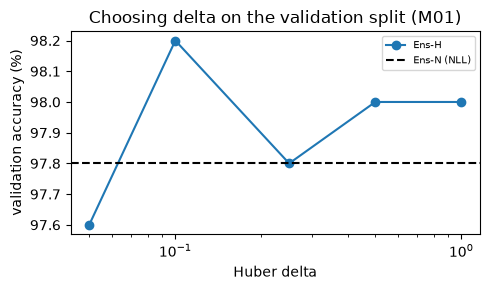

In [15]:
t0 = time.time()
# Choose the Huber delta on the attacker's VALIDATION images (true labels; never the test set): an Ens-H committee on M01 queried from the noisy cloud for each delta.
tsel = "M01"; d = TD[tsel]; P_sel = QD[(sd0, tsel)]["real"]["P_pool"]
bank_sel = {"pool": (d["A_q"], P_sel)}
dl_rows = []
for dl in DELTA_GRID:
    sp = []
    for mbr in range(NC_DEFAULT):
        idx = np.random.default_rng([sd0, 99, mbr]).integers(0, len(d["A_q"]), len(d["A_q"]) // NC_DEFAULT)
        sp.append(dict(bank="pool", idx=idx, huber=True, layers=N_LAYERS, ansatz="L", seed=sd0 + 100 * mbr, epochs=epochs_for(len(idx)), init=None))
    pars = fit_specs(sp, bank_sel, CLONE_LR, sd0, delta=dl)
    vote = lambda X: (2 * np.stack([logits_of(p, "L", X).argmax(1) for p in pars]).sum(0) > NC_DEFAULT).astype(int)
    dl_rows.append(dict(delta=dl, val_acc=100 * float((vote(d["A_val"]) == d["y_val"]).mean())))
    print(f"  delta {dl}: validation accuracy of the Ens-H vote {dl_rows[-1]['val_acc']:.1f} %   [{time.time() - t0:.0f} s]", flush=True)
# an NLL committee on the same data as the reference
sp = []
for mbr in range(NC_DEFAULT):
    idx = np.random.default_rng([sd0, 99, mbr]).integers(0, len(d["A_q"]), len(d["A_q"]) // NC_DEFAULT)
    sp.append(dict(bank="pool", idx=idx, huber=False, layers=N_LAYERS, ansatz="L", seed=sd0 + 100 * mbr, epochs=epochs_for(len(idx)), init=None))
pars = fit_specs(sp, bank_sel, CLONE_LR, sd0)
nll_val = 100 * float(((2 * np.stack([logits_of(p, "L", d["A_val"]).argmax(1) for p in pars]).sum(0) > NC_DEFAULT).astype(int) == d["y_val"]).mean())
dl_df = pd.DataFrame(dl_rows).set_index("delta")
DELTA = float(dl_df["val_acc"].idxmax())                                                     # CHOICE: delta with the best validation accuracy (first one on ties)
print(dl_df.round(1).to_string(), f"\nNLL committee on the same data: validation accuracy {nll_val:.1f} %")
print(f"DELTA = {DELTA} (validation accuracy {dl_df.loc[DELTA, 'val_acc']:.1f} %)   [{time.time() - t0:.0f} s]")
plt.figure(figsize=(5, 3)); plt.plot(dl_df.index, dl_df["val_acc"], "o-", label="Ens-H"); plt.axhline(nll_val, color="k", ls="--", label="Ens-N (NLL)")
plt.xscale("log"); plt.xlabel("Huber delta"); plt.ylabel("validation accuracy (%)"); plt.title("Choosing delta on the validation split (M01)"); plt.legend(fontsize=7); plt.tight_layout(); plt.show()


## 7. Main experiment: the analogue of Table II and Fig. 4

For every task, the noise-free ("ideal") and the noisy ("real") cloud, and every scheme: accuracy on the test images against the **true** labels, averaged over the seeds. Class 1 is the positive class in the confusion matrices.

main experiment done (24 configurations x 6 schemes, 3 seed(s))   [371 s]


Table II analogue: test accuracy (%) against the TRUE labels, mean over 3 seed(s); 6000 queried images in 3 rounds, 1000 test images
      victim ideal  victim real  CloudLeak ideal  CloudLeak real  QuantumLeak (Ens-H) real  gain over CloudLeak real
task                                                                                                                
M01           94.6        94.43            91.23           92.60                     93.33                      0.73
M23           81.9        77.97            81.03           76.90                     77.07                      0.17
Ftt           83.1        81.97            81.47           81.67                     79.67                     -2.00
Fpd           79.8        78.40            79.77           78.10                     77.57                     -0.53

Fig. 4 analogue (noisy cloud): test accuracy (%) of the four schemes, plus the two 'plain' singles without CloudLeak's out-of-domain and adversarial queries
scheme 

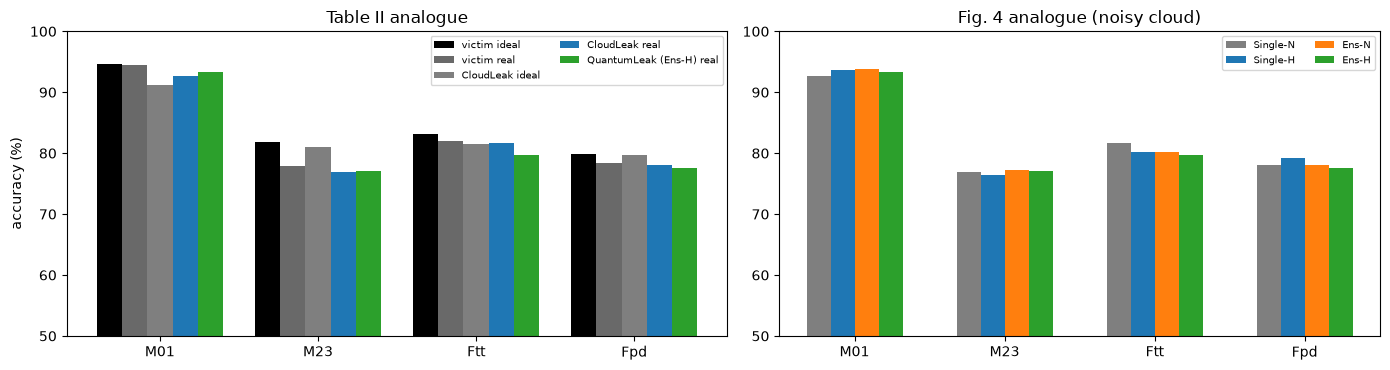

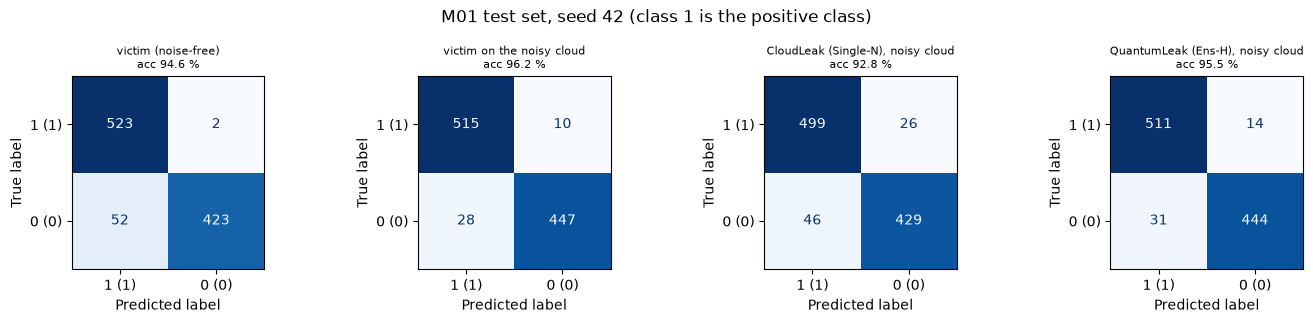

[373 s]


In [16]:
t0 = time.time()
ROWS = []
main_cfgs = [dict(seed=sd, task=t, scen=sc, nq=NQ_MAX, layers=N_LAYERS, ansatz="L", nc=NC_DEFAULT, schemes=SCHEMES + PLAIN) for sd in SEEDS for t in TASKS for sc in ("ideal", "real")]
ROWS += run_configs(main_cfgs)                                    # all seeds together: many clones train in one batch
print(f"main experiment done ({len(main_cfgs)} configurations x {len(SCHEMES + PLAIN)} schemes, {len(SEEDS)} seed(s))   [{time.time() - t0:.0f} s]", flush=True)
RES = pd.DataFrame(ROWS)
MAIN = RES[(RES.nq == NQ_MAX) & (RES.layers == N_LAYERS) & (RES.ansatz == "L") & (RES.nc == NC_DEFAULT)]

# ---- Table II analogue ----
def mean_(sel): return float(sel.acc.mean())
tab2 = []
for t in TASKS:
    mt = MAIN[MAIN.task == t]
    vi = 100 * VIC[t]["ideal_acc"]; vr = 100 * float(np.mean([QD[(s, t)]["vacc"] for s in SEEDS]))
    cl_i = mean_(mt[(mt.scen == "ideal") & (mt.scheme == "Single-N")]); cl_r = mean_(mt[(mt.scen == "real") & (mt.scheme == "Single-N")])
    ql = mean_(mt[(mt.scen == "real") & (mt.scheme == "Ens-H")])
    tab2.append({"task": t, "victim ideal": vi, "victim real": vr, "CloudLeak ideal": cl_i, "CloudLeak real": cl_r, "QuantumLeak (Ens-H) real": ql, "gain over CloudLeak real": ql - cl_r})
TAB2 = pd.DataFrame(tab2).set_index("task")
print(f"Table II analogue: test accuracy (%) against the TRUE labels, mean over {len(SEEDS)} seed(s); {NQ_MAX} queried images in {M_ROUNDS} rounds, {N_TEST} test images")
print(TAB2.round(2).to_string())

# ---- Fig. 4 analogue: the four schemes, noisy cloud ----
F4 = MAIN[MAIN.scen == "real"].groupby(["task", "scheme"]).acc.agg(["mean", "std"]).unstack("scheme")
acc4 = F4["mean"].reindex(index=TASKS, columns=SCHEMES + PLAIN)
print("\nFig. 4 analogue (noisy cloud): test accuracy (%) of the four schemes, plus the two 'plain' singles without CloudLeak's out-of-domain and adversarial queries")
print(acc4.round(2).to_string())
if len(SEEDS) > 1:
    print("\nstandard deviation over seeds"); print(F4["std"].reindex(index=TASKS, columns=SCHEMES + PLAIN).round(2).to_string())
print("\nFidelity (agreement with the noise-free victim on the test images, %), noisy cloud")
print(MAIN[MAIN.scen == "real"].groupby(["task", "scheme"]).agree.mean().unstack("scheme").reindex(index=TASKS, columns=SCHEMES + PLAIN).round(1).to_string())
print("\nnumber of queries the attacker pays for (per scheme)"); print(MAIN[(MAIN.scen == "real") & (MAIN.task == TASKS[0]) & (MAIN.seed == SEEDS[0])][["scheme", "queries"]].to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw=dict(width_ratios=[1.1, 1]))
w = 0.16; cols = ["tab:gray", "tab:blue", "tab:orange", "tab:green"]
cats = [("victim ideal", "k"), ("victim real", "dimgray"), ("CloudLeak ideal", "tab:gray"), ("CloudLeak real", "tab:blue"), ("QuantumLeak (Ens-H) real", "tab:green")]
for j, (c_, col) in enumerate(cats): ax[0].bar(np.arange(len(TASKS)) + (j - 2) * 0.16, TAB2[c_].values, 0.16, label=c_, color=col)
ax[0].set_xticks(range(len(TASKS))); ax[0].set_xticklabels(TASKS); ax[0].set_ylim(50, 100); ax[0].set_ylabel("accuracy (%)"); ax[0].legend(fontsize=7, ncol=2); ax[0].set_title("Table II analogue")
for j, sc_ in enumerate(SCHEMES): ax[1].bar(np.arange(len(TASKS)) + (j - 1.5) * w, acc4[sc_].values, w, label=sc_, color=cols[j])
ax[1].set_xticks(range(len(TASKS))); ax[1].set_xticklabels(TASKS); ax[1].set_ylim(50, 100); ax[1].legend(fontsize=7, ncol=2); ax[1].set_title("Fig. 4 analogue (noisy cloud)")
plt.tight_layout(); plt.show()

# ---- confusion matrices, first task and seed (class 1 is the positive class) ----
t_cm, s_cm = TASKS[0], SEEDS[0]; yt = TD[t_cm]["y_te"]
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
for a, (name, pred) in zip(ax, [("victim (noise-free)", VIC[t_cm]["ideal_pred"]), ("victim on the noisy cloud", QD[(s_cm, t_cm)]["vpred"]),
                                ("CloudLeak (Single-N), noisy cloud", PREDS[(s_cm, t_cm, "real", NQ_MAX, N_LAYERS, "L", NC_DEFAULT, "Single-N")]),
                                ("QuantumLeak (Ens-H), noisy cloud", PREDS[(s_cm, t_cm, "real", NQ_MAX, N_LAYERS, "L", NC_DEFAULT, "Ens-H")])]):
    ConfusionMatrixDisplay(confusion_matrix(yt, pred, labels=[1, 0]), display_labels=[f"{class_names(t_cm)[1]} (1)", f"{class_names(t_cm)[0]} (0)"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{name}\nacc {100 * (pred == yt).mean():.1f} %", fontsize=8)
plt.suptitle(f"{t_cm} test set, seed {s_cm} (class 1 is the positive class)"); plt.tight_layout(); plt.show()
print(f"[{time.time() - t0:.0f} s]")


### 7b. Extension: a noisier cloud

This is **not** an experiment of the paper. The paper's central observation is that the noise hurts the *clones* more than it hurts the victim (CloudLeak loses up to 10 points, the victim 1 to 3). With the noise scale that reproduces the victims' small
accuracy drop, the cloud labels are still mostly the labels of the noise-free victim, so there is little for an ensemble or a robust loss to repair. To see what happens when the labels are really corrupted, we repeat the four schemes on a cloud with `STRESS_FACTOR` times the calibrated `NOISE_LEVEL`
(new queries on the same simulated days, same training budgets). Only the noisy-cloud scenario is run.

  noise level 1.5, seed 42: queried 4 tasks x (6000 + 512 images) in 3 rounds   [7 s]


  noise level 1.5, seed 43: queried 4 tasks x (6000 + 512 images) in 3 rounds   [14 s]


  noise level 1.5, seed 44: queried 4 tasks x (6000 + 512 images) in 3 rounds   [19 s]


Stronger noise: NOISE_LEVEL x 1.5 = 1.5; test accuracy (%), mean over 3 seed(s); mean victim drop 4.15 points (calibrated device: 2.19)
     victim ideal  victim noisy  Single-N  Single-H  Ens-N  Ens-H  Ens-H - Single-N
M01          94.6         91.83     93.17     90.83  92.67  92.10             -1.07
M23          81.9         75.20     74.83     73.77  74.47  73.60             -1.23
Ftt          83.1         80.00     79.23     79.33  78.93  78.67             -0.57
Fpd          79.8         75.77     75.47     74.97  75.80  75.60              0.13

standard deviation over seeds
scheme  Single-N  Single-H  Ens-N  Ens-H
task                                    
M01         2.85      0.95   2.03   1.47
M23         1.07      1.69   0.21   1.08
Ftt         2.80      2.75   1.50   1.33
Fpd         4.29      2.50   3.22   3.78

mean gain of Ens-H over Single-N (CloudLeak) over the four tasks: stronger noise -0.68 points; calibrated noise -0.41 points


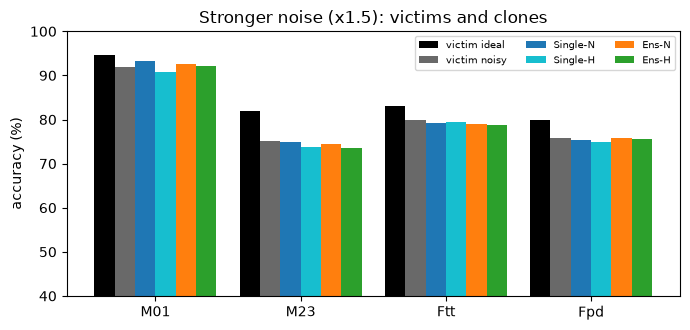

[191 s]


In [17]:
t0 = time.time()
# Extension (not an experiment of the paper): the same four schemes when the cloud is noisier than the calibrated device, STRESS_FACTOR x NOISE_LEVEL.
# The paper's clones lose more accuracy to the noise than the victim itself does; with the calibrated (mild) noise this does not happen here, so we ask what changes when it is stronger.
NOISE_STRESS = round(STRESS_FACTOR * NOISE_LEVEL, 3)
QD_STRESS = build_QD(NOISE_STRESS, SEEDS, salt=500)
_K, _P = dict(KEEP), dict(PREDS)                                                      # keep the trained parameters/predictions of the main experiment untouched
stress_cfgs = [dict(seed=sd, task=t, scen="real", nq=NQ_MAX, layers=N_LAYERS, ansatz="L", nc=NC_DEFAULT, schemes=SCHEMES) for sd in SEEDS for t in TASKS]
RES_STRESS = pd.DataFrame(run_configs(stress_cfgs, Q=QD_STRESS))
KEEP.clear(); KEEP.update(_K); PREDS.clear(); PREDS.update(_P)
vr = {t: 100 * float(np.mean([QD_STRESS[(s, t)]["vacc"] for s in SEEDS])) for t in TASKS}
st_acc = RES_STRESS.groupby(["task", "scheme"]).acc.mean().unstack("scheme").reindex(index=TASKS, columns=SCHEMES)
st_std = RES_STRESS.groupby(["task", "scheme"]).acc.std().unstack("scheme").reindex(index=TASKS, columns=SCHEMES)
st_tab = pd.concat([pd.Series({t: 100 * VIC[t]["ideal_acc"] for t in TASKS}, name="victim ideal"), pd.Series(vr, name="victim noisy")], axis=1).join(st_acc)
st_tab["Ens-H - Single-N"] = st_tab["Ens-H"] - st_tab["Single-N"]
print(f"Stronger noise: NOISE_LEVEL x {STRESS_FACTOR} = {NOISE_STRESS}; test accuracy (%), mean over {len(SEEDS)} seed(s); mean victim drop {np.mean([100 * VIC[t]['ideal_acc'] - vr[t] for t in TASKS]):.2f} points (calibrated device: {cal_df.loc[NOISE_LEVEL, 'mean_drop']:.2f})")
print(st_tab.round(2).to_string())
if len(SEEDS) > 1: print("\nstandard deviation over seeds"); print(st_std.round(2).to_string())
mean_gain = float(st_tab["Ens-H - Single-N"].mean())
print(f"\nmean gain of Ens-H over Single-N (CloudLeak) over the four tasks: stronger noise {mean_gain:+.2f} points; calibrated noise {float(TAB2['gain over CloudLeak real'].mean()):+.2f} points")
fig, ax = plt.subplots(figsize=(7, 3.4)); w = 0.16
for j, (c_, col) in enumerate([("victim ideal", "k"), ("victim noisy", "dimgray"), ("Single-N", "tab:blue"), ("Single-H", "tab:cyan"), ("Ens-N", "tab:orange"), ("Ens-H", "tab:green")]):
    ax.bar(np.arange(len(TASKS)) + (j - 2.5) * 0.14, st_tab[c_].values, 0.14, label=c_, color=col)
ax.set_xticks(range(len(TASKS))); ax.set_xticklabels(TASKS); ax.set_ylim(40, 100); ax.set_ylabel("accuracy (%)"); ax.legend(fontsize=7, ncol=3); ax.set_title(f"Stronger noise (x{STRESS_FACTOR}): victims and clones")
plt.tight_layout(); plt.show()
print(f"[{time.time() - t0:.0f} s]")


## 8. Sensitivity studies: Figs. 5 to 8

* **Fig. 5:** the clone ansatz (L2, A1, A2), tasks `SWEEP_TASKS`.
* **Fig. 6:** the committee size N = 3, 5, 7 for Ens-N and Ens-H, tasks `SWEEP_TASKS`.
* **Figs. 7 and 8:** the query budget and the number of VQC layers L1, L2, L3 (task M01).

All three studies are averaged over the seeds of `SWEEP_SEEDS` (each seed is a different simulated day, different bootstrap samples and different initial parameters). Differences of one to two points are within the seed-to-seed spread.

sweeps done (48 configurations, seed(s) [42, 43, 44])   [727 s]


Fig. 5 analogue: accuracy (%) of the four schemes for three clone ansatzes, mean over tasks ['M01', 'M23'] and seed(s) [42, 43, 44]
scheme                            Single-N  Single-H  Ens-N  Ens-H
L2 (victim ansatz)                   84.75     85.05  85.57  85.20
A1 (fixed CNOTs)                     83.62     83.30  85.62  85.38
A2 (parameterised 2-qubit gates)     82.37     82.37  83.85  83.22

Fig. 6 analogue: accuracy (%) against the committee size N, mean over tasks ['M01', 'M23'] and seeds
scheme  Ens-H  Ens-N
nc                  
3       85.35  85.15
5       85.20  85.57
7       85.35  85.52

Figs. 7/8 analogue: M01 accuracy (%) for every scheme, number of VQC layers L and query budget
nq                1500   3000   6000
scheme   layers                     
Ens-H    1       91.97  93.17  91.60
         2       93.33  93.93  93.33
         3       93.77  94.00  94.27
Ens-N    1       90.87  92.00  90.97
         2       93.63  93.73  93.87
         3       93.77  94.13  94.27
S

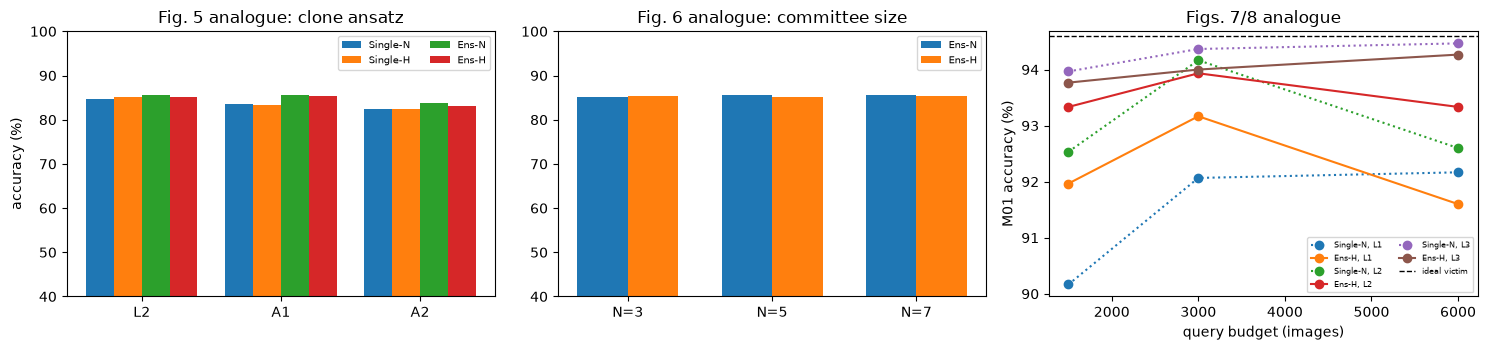

[731 s]


In [18]:
import itertools
t0 = time.time()
SW_ROWS = []
sweep_cfgs = []
for sd, t in itertools.product(SWEEP_SEEDS, SWEEP_TASKS):
    for ans in ("A1", "A2"):                                                    # Fig. 5: other ansatzes (L2 comes from the main experiment)
        sweep_cfgs.append(dict(seed=sd, task=t, scen="real", nq=NQ_MAX, layers=N_LAYERS, ansatz=ans, nc=NC_DEFAULT, schemes=SCHEMES))
    for nc in COMMITTEES:                                                       # Fig. 6: committee size (N = 5 comes from the main experiment)
        if nc != NC_DEFAULT: sweep_cfgs.append(dict(seed=sd, task=t, scen="real", nq=NQ_MAX, layers=N_LAYERS, ansatz="L", nc=nc, schemes=["Ens-N", "Ens-H"]))
for sd, L_ in itertools.product(SWEEP_SEEDS, LAYER_SWEEP):                  # Figs. 7 and 8: query budget x number of VQC layers, task M01
    for nq in BUDGETS:
        if not (nq == NQ_MAX and L_ == N_LAYERS):
            sweep_cfgs.append(dict(seed=sd, task="M01", scen="real", nq=nq, layers=L_, ansatz="L", nc=NC_DEFAULT, schemes=SCHEMES))
SW_ROWS += run_configs(sweep_cfgs)
print(f"sweeps done ({len(sweep_cfgs)} configurations, seed(s) {SWEEP_SEEDS})   [{time.time() - t0:.0f} s]", flush=True)
ALL = pd.concat([RES, pd.DataFrame(SW_ROWS)], ignore_index=True)
REAL = ALL[(ALL.scen == "real") & ALL.seed.isin(SWEEP_SEEDS)]               # Figs. 5 to 8 use the seed(s) of the sweeps

# ---- Fig. 5: ansatz ----
a5 = REAL[(REAL.nq == NQ_MAX) & (REAL.nc == NC_DEFAULT) & (REAL.layers == N_LAYERS) & REAL.task.isin(SWEEP_TASKS) & REAL.scheme.isin(SCHEMES)]
fig5 = a5.groupby(["ansatz", "scheme"]).acc.mean().unstack("scheme").reindex(index=["L", "A1", "A2"], columns=SCHEMES)
fig5.index = ["L2 (victim ansatz)", "A1 (fixed CNOTs)", "A2 (parameterised 2-qubit gates)"]
print(f"Fig. 5 analogue: accuracy (%) of the four schemes for three clone ansatzes, mean over tasks {SWEEP_TASKS} and seed(s) {SWEEP_SEEDS}"); print(fig5.round(2).to_string())
# ---- Fig. 6: committee size ----
a6 = REAL[(REAL.nq == NQ_MAX) & (REAL.layers == N_LAYERS) & (REAL.ansatz == "L") & REAL.task.isin(SWEEP_TASKS) & REAL.scheme.isin(["Ens-N", "Ens-H"])]
fig6 = a6.groupby(["nc", "scheme"]).acc.mean().unstack("scheme").reindex(index=COMMITTEES)
print(f"\nFig. 6 analogue: accuracy (%) against the committee size N, mean over tasks {SWEEP_TASKS} and seeds"); print(fig6.round(2).to_string())
# ---- Figs. 7 and 8: budget x layers on M01 ----
a7 = REAL[(REAL.task == "M01") & (REAL.ansatz == "L") & (REAL.nc == NC_DEFAULT) & REAL.scheme.isin(SCHEMES)]
fig7 = a7.groupby(["scheme", "layers", "nq"]).acc.mean().unstack("nq")
print("\nFigs. 7/8 analogue: M01 accuracy (%) for every scheme, number of VQC layers L and query budget"); print(fig7.round(2).to_string())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
w = 0.2
for j, sc_ in enumerate(SCHEMES): ax[0].bar(np.arange(3) + (j - 1.5) * w, fig5[sc_].values, w, label=sc_)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(["L2", "A1", "A2"]); ax[0].set_ylim(40, 100); ax[0].set_ylabel("accuracy (%)"); ax[0].legend(fontsize=7, ncol=2); ax[0].set_title("Fig. 5 analogue: clone ansatz")
for j, sc_ in enumerate(["Ens-N", "Ens-H"]): ax[1].bar(np.arange(len(COMMITTEES)) + (j - 0.5) * 0.35, fig6[sc_].values, 0.35, label=sc_)
ax[1].set_xticks(range(len(COMMITTEES))); ax[1].set_xticklabels([f"N={n}" for n in COMMITTEES]); ax[1].set_ylim(40, 100); ax[1].legend(fontsize=7); ax[1].set_title("Fig. 6 analogue: committee size")
for L_ in LAYER_SWEEP:
    for sc_, ls in [("Single-N", ":"), ("Ens-H", "-")]:
        r_ = fig7.loc[(sc_, L_)]; ax[2].plot(BUDGETS, r_.reindex(BUDGETS).values, ls, marker="o", label=f"{sc_}, L{L_}")
ax[2].axhline(100 * VIC["M01"]["ideal_acc"], color="k", ls="--", lw=1, label="ideal victim"); ax[2].set_xlabel("query budget (images)"); ax[2].set_ylabel("M01 accuracy (%)"); ax[2].legend(fontsize=6, ncol=2); ax[2].set_title("Figs. 7/8 analogue")
plt.tight_layout(); plt.show()
print(f"[{time.time() - t0:.0f} s]")


## 9. Classical models on the same stolen answers

A classical baseline on exactly the same inputs: random forest, SVC with an RBF kernel and logistic regression, trained on the 8 PCA numbers of the query images and the arg-max label returned by the cloud, evaluated on the same test images. The last row is a reference
that is **not** a stealing attack: a random forest trained on the true labels of the same images.

In [19]:
t0 = time.time()
# Classical models trained on EXACTLY the same inputs as the quantum clones: the 8 PCA numbers of the NQ_MAX query images and the hard label
# (argmax) of the answer the cloud returned; evaluated on the same test images against the true labels.
cl_rows = []
for seed in SEEDS:
    for t in TASKS:
        d = TD[t]
        for scen in ("ideal", "real"):
            yl = QD[(seed, t)][scen]["P_pool"].argmax(1)
            for name, mk in [("Random forest", lambda: RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)),
                             ("SVC (rbf)", lambda: SVC(kernel="rbf", C=1.0, gamma="scale")),
                             ("Logistic regression", lambda: LogisticRegression(max_iter=1000))]:
                mdl = mk().fit(d["Z_q"], yl); cl_rows.append(dict(seed=seed, task=t, scen=scen, model=name, acc=100 * float((mdl.predict(d["Z_te"]) == d["y_te"]).mean())))
        cl_rows.append(dict(seed=seed, task=t, scen="true labels", model="Random forest (reference, true labels)",
                            acc=100 * float((RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(d["Z_q"], d["y_q"]).predict(d["Z_te"]) == d["y_te"]).mean())))
CLS = pd.DataFrame(cl_rows)
cls_tab = CLS.groupby(["model", "scen", "task"]).acc.mean().unstack("task").reindex(columns=TASKS)
q_ideal = MAIN[(MAIN.scen == "ideal")].groupby(["scheme", "task"]).acc.mean().unstack("task").reindex(columns=TASKS)
q_real = MAIN[(MAIN.scen == "real")].groupby(["scheme", "task"]).acc.mean().unstack("task").reindex(columns=TASKS)
qnn_rows = [pd.Series(df.loc[s].values, index=TASKS, name=(f"QNN clone {s}", scen)) for scen, df in [("ideal", q_ideal), ("real", q_real)] for s in ["Single-N", "Ens-H"]]
qnn_tab = pd.DataFrame(qnn_rows); qnn_tab.index = pd.MultiIndex.from_tuples(qnn_tab.index, names=["model", "scen"])
cmp_cls = pd.concat([cls_tab.round(2), qnn_tab.round(2)])
print("Test accuracy (%) of classical clones and QNN clones trained on the same cloud answers (rows: model, scenario)")
print(cmp_cls.to_string())
print(f"[{time.time() - t0:.0f} s]")


Test accuracy (%) of classical clones and QNN clones trained on the same cloud answers (rows: model, scenario)
                                                      M01    M23    Ftt    Fpd
model                                  scen                                   
Logistic regression                    ideal        97.60  89.00  93.30  89.30
                                       real         98.93  81.97  91.50  88.40
Random forest                          ideal        96.70  86.80  87.50  82.60
                                       real         96.70  81.23  85.43  81.07
Random forest (reference, true labels) true labels  99.80  96.90  98.10  96.90
SVC (rbf)                              ideal        95.60  84.50  85.50  82.60
                                       real         96.07  79.97  84.33  81.60
QNN clone Single-N                     ideal        91.23  81.03  81.47  79.77
QNN clone Ens-H                        ideal        91.97  79.73  80.50  78.33
QNN clone Single-N  

## Quantum Circuit Architecture

The first figure is the circuit that the simulated cloud executes for one query of the victim (the very object that is sent to Aer in Section 4): amplitude encoding (`set_statevector`), one noisy `id` gate per qubit for the compiled encoding, the two
VQC layers (RZ, RY, RZ, CRX ring) and the measurement. The next five figures show each distinct clone architecture of the "QNN zoo" (L1, L2, L3, A1, A2) with trained parameters of one Ens-H committee member, drawn from the same gate list the PyTorch simulator runs;
a cell asserts, for each of them, that Qiskit's exact `Statevector` gives the same class scores and decisions as the PyTorch model that was trained. The table gives qubit count, depth and the number of trainable parameters.

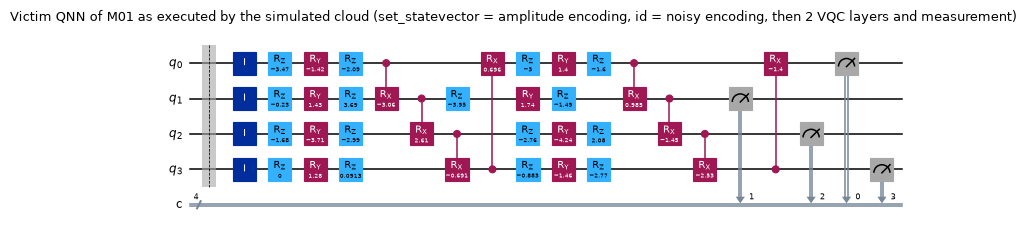

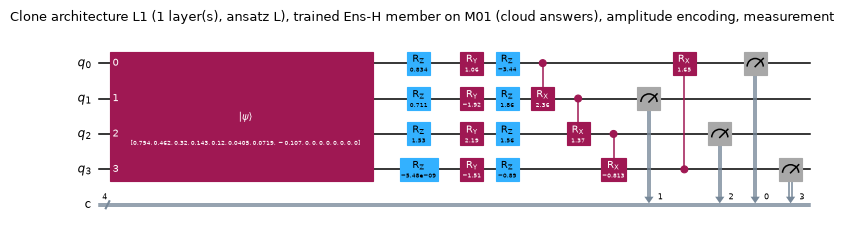

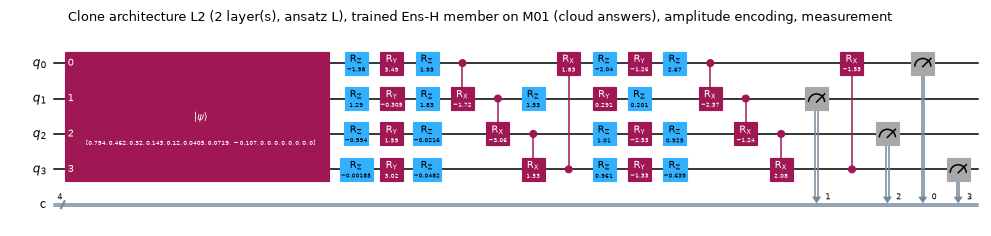

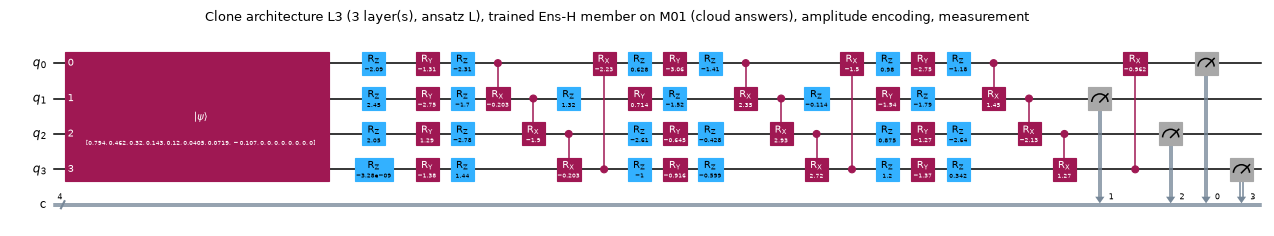

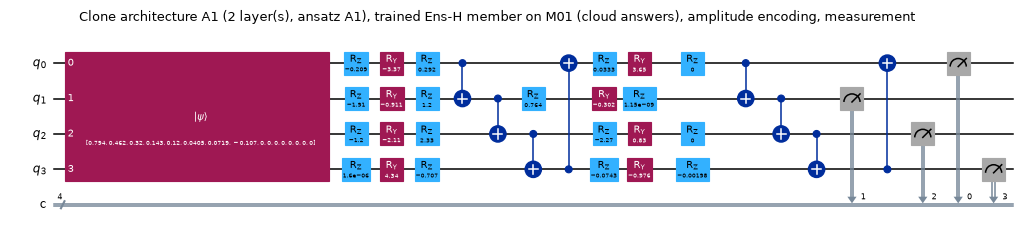

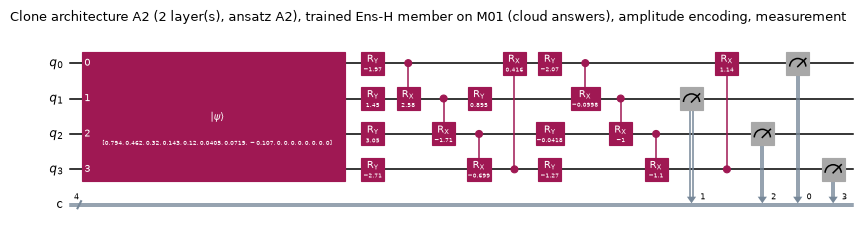

                                    qubits  depth (VQC only)  depth (encoding + VQC + measure, basis gates)  1-qubit-gate params  2-qubit-gate params  trainable params                 gates in the VQC  max |Qiskit - PyTorch| class score
architecture                                                                                                                                                                                                                                
victim (= L2, as run in the cloud)       4                14                                             49                   24                    8                32    {'rz': 16, 'ry': 8, 'crx': 8}                                 NaN
L1                                       4                 7                                             96                   12                    4                16     {'rz': 8, 'ry': 4, 'crx': 4}                        1.770584e-12
L2                                       4          

In [20]:
from IPython.display import display
t_c = "M01"; amp0 = TD[t_c]["A_te"][0].astype(complex)

# 1) the circuit the QNN-as-a-Service executes for one query of the victim (this is the object sent to Aer in Section 4)
par_v = VIC[t_c]["params"]
qc_victim = cloud_circuit(amp0, var_circuit(par_v))                                  # logical circuit: encoding, noisy-id, VQC, measurement
qc_victim_exec = cloud_circuit(amp0, transpile(var_circuit(par_v), basis_gates=CLOUD_BASIS, optimization_level=0))     # as executed in the cloud's basis gates
fig = qc_victim.draw("mpl", fold=45, scale=0.55); fig.suptitle(f"Victim QNN of {t_c} as executed by the simulated cloud (set_statevector = amplitude encoding, id = noisy encoding, then 2 VQC layers and measurement)", fontsize=9)
display(fig); plt.close(fig)

# 2) the distinct clone architectures (trained parameters of one committee member / clone), drawn from the same gate list the PyTorch simulator runs
ARCHS = [("L1", 1, "L"), ("L2", 2, "L"), ("L3", 3, "L"), ("A1", 2, "A1"), ("A2", 2, "A2")]
def clone_circuit(params, ansatz):
    qc = QuantumCircuit(N_QUBITS, N_QUBITS); qc.initialize(amp0 / np.linalg.norm(amp0), range(N_QUBITS))
    qc.compose(var_circuit(params, N_QUBITS, ansatz), inplace=True); qc.measure(range(N_QUBITS), range(N_QUBITS)); return qc
arch_rows = []
chk = TD[t_c]["A_te"][:100]
for name, Lx, ans in ARCHS:
    par = KEEP[(sd0, t_c, "real", NQ_MAX, Lx, ans, NC_DEFAULT, "Ens-H")]
    qc_c = clone_circuit(par, ans)
    fig = qc_c.draw("mpl", fold=45, scale=0.55); fig.suptitle(f"Clone architecture {name} ({Lx} layer(s), ansatz {ans}), trained Ens-H member on {t_c} (cloud answers), amplitude encoding, measurement", fontsize=9)
    display(fig); plt.close(fig)
    # equivalence: Qiskit's exact Statevector gives the same class scores and decisions as the PyTorch model that was trained
    sc_torch = logits_of(par, ans, chk)
    sc_qiskit = np.array([[sum(z[:2]), sum(z[2:])] for z in (qiskit_z(v, par, N_QUBITS, ans) for v in chk)])
    assert np.abs(sc_qiskit - sc_torch).max() < 1e-8 and (sc_qiskit.argmax(1) == sc_torch.argmax(1)).all()
    ex = transpile(qc_c, basis_gates=CLOUD_BASIS, optimization_level=0)
    arch_rows.append({"architecture": name, "qubits": N_QUBITS, "depth (VQC only)": var_circuit(par, N_QUBITS, ans).depth(), "depth (encoding + VQC + measure, basis gates)": ex.depth(),
                      "1-qubit-gate params": n_params(4, Lx, ans)[0], "2-qubit-gate params": n_params(4, Lx, ans)[1], "trainable params": sum(n_params(4, Lx, ans)),
                      "gates in the VQC": dict(var_circuit(par, N_QUBITS, ans).count_ops()), "max |Qiskit - PyTorch| class score": float(np.abs(sc_qiskit - sc_torch).max())})
arch_rows.insert(0, {"architecture": "victim (= L2, as run in the cloud)", "qubits": N_QUBITS, "depth (VQC only)": var_circuit(par_v).depth(), "depth (encoding + VQC + measure, basis gates)": qc_victim_exec.depth(),
                     "1-qubit-gate params": n_params(4, 2)[0], "2-qubit-gate params": n_params(4, 2)[1], "trainable params": sum(n_params(4, 2)), "gates in the VQC": dict(var_circuit(par_v).count_ops()),
                     "max |Qiskit - PyTorch| class score": np.nan})
print(pd.DataFrame(arch_rows).set_index("architecture").to_string())
print("\nAll five clone circuits pass the equivalence check (Qiskit Statevector == PyTorch simulator, identical decisions on 100 test images).")
print(f"Ensembles train {NC_DEFAULT} (or {COMMITTEES}) such circuits per scheme; every committee member has the architecture of the row above it.")
print("Assumptions where the paper omits circuit details: read-out = <Z0>+<Z1> versus <Z2>+<Z3> of the 4 qubits; the CRX gates form a ring (q -> q+1 mod 4); 8 PCA numbers are zero-padded to 16 amplitudes; the cloud's amplitude-encoding circuit is represented by one noisy id gate per qubit; the gate lists of A1 and A2 follow the counts in the paper (12/4 and 4/4 gates per block) but their exact gate types are a CHOICE.")


## 10. Optional: the victim on a real IBM machine

Only runs when `IBM_TOKEN` is set in the configuration cell (a personal IBM Quantum API key; never commit it). It runs the M01 victim for 50 test images on the least busy device and compares the accuracy with the simulated cloud. Skipped by default.

In [21]:
if not IBM_TOKEN:
    print("IBM_TOKEN is empty -> real-hardware cell skipped (the simulated cloud above is used everywhere).")
else:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
    backend = service.least_busy(operational=True, simulator=False)
    amps = TD["M01"]["A_te"][:50]
    circs = []
    for v in amps:
        qc = QuantumCircuit(4, 4); qc.initialize(v, range(4)); qc.compose(var_circuit(VIC["M01"]["params"]), inplace=True); qc.measure(range(4), range(4)); circs.append(qc)
    isa = transpile(circs, backend=backend, optimization_level=1)
    res = SamplerV2(mode=backend).run(isa, shots=SHOTS).result()
    raw = np.array([sum(c * SGN[int(k, 2)] for k, c in res[i].data.c.get_counts().items()) / SHOTS for i in range(len(circs))])
    acc = (head(torch.tensor(raw)).argmax(1).numpy() == TD["M01"]["y_te"][:50]).mean()
    print(f"{backend.name}: M01 victim accuracy on 50 test images {100 * acc:.1f} % (ideal {100 * VIC['M01']['ideal_acc']:.1f} %)")


IBM_TOKEN is empty -> real-hardware cell skipped (the simulated cloud above is used everywhere).


## 11. Side by side with the paper

Verdicts: **reproduced** (within 2 accuracy points of the paper's number, or the qualitative statement holds), **not reached** / **exceeded** (outside the tolerance, direction given), **cannot be checked**.
Because the cloud is a simulation with one fitted noise scale and CloudLeak is a simplified re-implementation, absolute accuracies are expected to differ from the paper's; the orderings and trends are the robust part.

In [22]:
# Paper values, Table II (order of TASKS = M01, M23, Ftt, Fpd) and Figs. 4-8
PAPER = pd.DataFrame({"victim ideal": [89.55, 84.22, 77.02, 76.92], "victim real": [86.18, 81.44, 75.47, 76.05],
                      "CloudLeak ideal": [85.87, 81.01, 73.4, 72.5], "CloudLeak real": [79.40, 76.5, 70.1, 69.2],
                      "QuantumLeak (Ens-H) real": [86.75, 81.49, 75.67, 75.84], "gain over CloudLeak real": [7.35, 4.99, 5.57, 6.64]},
                     index=["M01", "M23", "Ftt", "Fpd"]).loc[TASKS]
VERD = []
def claim(cid, text, paper, here, verdict, note=""):
    VERD.append({"#": cid, "claim in the paper": text, "paper": paper, "this notebook": here, "verdict": verdict, "note": note})
def per_task(col, tol=2.0):
    diff = (TAB2[col] - PAPER[col]); ok = int((diff.abs() <= tol).sum())
    verdict = "reproduced" if ok == len(TASKS) else (f"reproduced for {ok} of {len(TASKS)} tasks" if ok else ("not reached" if diff.mean() < 0 else "exceeded"))
    return verdict, ", ".join(f"{t} {TAB2.loc[t, col]:.1f} ({diff[t]:+.1f})" for t in TASKS), ", ".join(f"{t} {PAPER.loc[t, col]:.1f}" for t in TASKS)

v, h, p = per_task("victim ideal");        claim("C1", "noise-free victim accuracy (Table II)", p, h, v, "tolerance 2 points; different PCA/amplitude-encoding details, simulator and training budget")
v, h, p = per_task("victim real");         claim("C2", "victim accuracy on the noisy NISQ device (Table II)", p, h, v, "the MEAN drop over the four victims is fitted (NOISE_LEVEL), so the mean of C2 is partly fitted; the split over the tasks is a prediction")
drop_here = TAB2["victim ideal"] - TAB2["victim real"]; drop_paper = PAPER["victim ideal"] - PAPER["victim real"]
ok = int(((drop_here - drop_paper).abs() <= 2).sum())
claim("C3", "noise lowers the victim's accuracy by 3.4 / 2.8 / 1.6 / 0.9 points (Table II)", ", ".join(f"{t} {drop_paper[t]:.1f}" for t in TASKS), ", ".join(f"{t} {drop_here[t]:.1f}" for t in TASKS),
      "reproduced" if ok == len(TASKS) else f"reproduced for {ok} of {len(TASKS)} tasks", "only the mean drop (2.14 points) is fitted; the per-task drops are predictions of the simulated device and vary strongly with the simulated day")
v, h, p = per_task("CloudLeak ideal");     claim("C4", "CloudLeak clone trained on noise-free answers (Table II)", p, h, v, "CloudLeak is re-implemented as a simplified version (out-of-domain + FGSM queries, no transfer learning)")
v, h, p = per_task("CloudLeak real");      claim("C5", "CloudLeak clone trained on noisy-cloud answers (Table II)", p, h, v, "see C4")
v, h, p = per_task("QuantumLeak (Ens-H) real"); claim("C6", "QuantumLeak (Ens-H) clone, noisy cloud (Table II)", p, h, v, "")
gain = TAB2["gain over CloudLeak real"]
claim("C7", "QuantumLeak beats CloudLeak on every task (Table II)", "4 of 4 tasks", f"{int((gain > 0).sum())} of {len(TASKS)} tasks", "reproduced" if (gain > 0).all() else "not reached",
      "gains: " + ", ".join(f"{t} {gain[t]:+.2f}" for t in TASKS))
claim("C8", "QuantumLeak improves accuracy by 4.99 ... 7.35 points over CloudLeak (abstract)", "+4.99 ... +7.35", f"{gain.min():+.2f} ... {gain.max():+.2f} (mean {gain.mean():+.2f})",
      "reproduced" if (gain.mean() >= 4.99 - 2 and gain.mean() <= 7.35 + 2) else ("exceeded" if gain.mean() > 7.35 + 2 else "not reached"), "range check: mean gain within the paper's range widened by 2 points")
gap10 = (TAB2["victim ideal"] - TAB2["CloudLeak real"])
claim("C9", "CloudLeak on the noisy cloud is up to 10.15 points below the victim (Sec. III-B)", "10.15 (M01)", f"max {gap10.max():.2f} ({gap10.idxmax()}); " + ", ".join(f"{t} {gap10[t]:.1f}" for t in TASKS),
      "reproduced" if abs(gap10.max() - 10.15) <= 2 else ("not reached" if gap10.max() < 10.15 else "exceeded"), "")
claim("C10", "QuantumLeak is comparable to the ideal victim on some tasks (Sec. VII-A)", "gap to ideal victim: 2.8 / 2.7 / 1.4 / 1.1", ", ".join(f"{t} {TAB2.loc[t, 'victim ideal'] - TAB2.loc[t, 'QuantumLeak (Ens-H) real']:.1f}" for t in TASKS),
      "reproduced" if (TAB2["victim ideal"] - TAB2["QuantumLeak (Ens-H) real"]).min() <= 3 else "not reached", "gap = ideal victim minus Ens-H on the noisy cloud; reproduced when at least one task is within 3 points")
# Fig. 4
best = [(t, acc4.loc[t, "Ens-H"] >= acc4.loc[t, SCHEMES].max() - 1e-9) for t in TASKS]
claim("C11", "Ens-H is the best of the four schemes on every task (Fig. 4)", "4 of 4 tasks", f"{sum(b for _, b in best)} of {len(TASKS)}", "reproduced" if all(b for _, b in best) else "not reached",
      "; ".join(f"{t}: " + ", ".join(f"{s} {acc4.loc[t, s]:.1f}" for s in SCHEMES) for t in TASKS))
hub_ok = [(t, fam, acc4.loc[t, f"{fam}-H"] >= acc4.loc[t, f"{fam}-N"]) for t in TASKS for fam in ("Single", "Ens")]
claim("C12", "Huber loss improves on NLL in all cases (Fig. 4)", f"8 of 8 (4 tasks x single/ensemble)", f"{sum(o for *_, o in hub_ok)} of {len(hub_ok)}", "reproduced" if all(o for *_, o in hub_ok) else "not reached",
      "fails: " + (", ".join(f"{t}/{f}" for t, f, o in hub_ok if not o) or "none"))
ens_ok = [(t, h_, acc4.loc[t, f"Ens-{h_}"] > acc4.loc[t, f"Single-{h_}"]) for t in TASKS for h_ in "NH"]
claim("C13", "the ensemble beats the single clone except Ens-N on M01 and Ftt (Fig. 4)", "6 of 8", f"{sum(o for *_, o in ens_ok)} of {len(ens_ok)}", "reproduced" if sum(o for *_, o in ens_ok) >= 6 else "not reached",
      "ensemble not better: " + (", ".join(f"{t}/Ens-{h_}" for t, h_, o in ens_ok if not o) or "none"))
# Fig. 5
l2, a1, a2 = fig5.iloc[0]["Ens-H"], fig5.iloc[1]["Ens-H"], fig5.iloc[2]["Ens-H"]
claim("C14", "the victim ansatz L2 is the best clone, A1 (fixed CNOTs) clearly the worst (Fig. 5)", "L2 > A2 > A1", f"Ens-H: L2 {l2:.1f}, A2 {a2:.1f}, A1 {a1:.1f}",
      "reproduced" if (l2 >= max(a1, a2) and a1 < a2 - 0.5) else ("partly (L2 best, A1 not clearly the worst)" if l2 >= max(a1, a2) else "not reached"), "A1/A2 gate lists are our reading of the paper's counts; a difference below 0.5 points counts as a tie")
# Fig. 6
e = fig6["Ens-H"]; en = fig6["Ens-N"]
mono = bool(e.is_monotonic_increasing and en.is_monotonic_increasing)
claim("C15", "accuracy grows with the committee size N = 3, 5, 7 with diminishing gains (Fig. 6)", "monotone, gain 3->5 > gain 5->7",
      f"Ens-H {e.iloc[0]:.1f} / {e.iloc[1]:.1f} / {e.iloc[2]:.1f}; Ens-N {en.iloc[0]:.1f} / {en.iloc[1]:.1f} / {en.iloc[2]:.1f}",
      ("reproduced" if (mono and (e.iloc[1] - e.iloc[0]) >= (e.iloc[2] - e.iloc[1])) else ("reproduced (monotone, gains not diminishing)" if mono else "not reached")), "")
# Figs. 7, 8
b_lo, b_hi = min(BUDGETS), max(BUDGETS)
g3 = fig7.loc[("Ens-H", 3), b_hi] - fig7.loc[("Ens-H", 3), b_lo]
claim("C16", "more queries raise the accuracy of the L3 clone: Ens-H 73.93 % (1500) -> 86.75 % (6000)", "+12.8 points", f"{fig7.loc[('Ens-H', 3), b_lo]:.1f} -> {fig7.loc[('Ens-H', 3), b_hi]:.1f} ({g3:+.1f})",
      "reproduced" if (g3 > 0 and abs(g3 - 12.82) <= 4) else ("reproduced (direction; size differs)" if g3 >= 2 else "not reached (change within the seed noise)"), "budgets here: " + ", ".join(map(str, BUDGETS)) + "; a change below 2 points is treated as noise")
d_l = fig7.loc[("Ens-H", 3), b_hi] - fig7.loc[("Ens-H", 1), b_hi]
claim("C17", "at a fixed budget more VQC layers give a higher accuracy (L3 > L1 at 6000 queries, Figs. 7/8)", "L3 86.75 vs L1 68.56", f"L3 {fig7.loc[('Ens-H', 3), b_hi]:.1f} vs L1 {fig7.loc[('Ens-H', 1), b_hi]:.1f}", "reproduced" if d_l >= 2 else "not reached (difference within the seed noise)", "a difference below 2 points is treated as noise")
mid = BUDGETS[1]; l1 = fig7.loc[("Ens-H", 1)]
claim("C18", "the shallow L1 clone peaks at 3000 queries and gets worse at 6000 (overfitting; 74.62 -> 68.56)", "-6.06 points", f"{l1[mid]:.1f} -> {l1[b_hi]:.1f} ({l1[b_hi] - l1[mid]:+.1f})", "reproduced" if l1[b_hi] <= l1[mid] - 2 else "not reached (difference within the seed noise)", "single run per cell in the paper; a drop below 2 points is treated as noise")
claim("C19", "L3 with 6000 queries reaches the accuracy of the victim (Sec. VII-D)", f"{PAPER.loc['M01', 'victim real']:.1f} (victim real)", f"L3 Ens-H {fig7.loc[('Ens-H', 3), b_hi]:.1f} vs noisy victim {TAB2.loc['M01', 'victim real']:.1f}",
      "reproduced" if abs(fig7.loc[("Ens-H", 3), b_hi] - TAB2.loc["M01", "victim real"]) <= 2 else ("exceeded" if fig7.loc[("Ens-H", 3), b_hi] > TAB2.loc["M01", "victim real"] else "not reached"), "")
claim("C20", "IBM hardware results (IBM_Auckland, 27 qubits) and defences (watermarking, PUF, dummy SWAPs)", "hardware runs; discussed defences", "simulated cloud only; defences not evaluated", "cannot be checked", "no hardware access here; Section V of the paper gives no experiment")
cmp_df = pd.DataFrame(VERD)
pd.set_option("display.max_colwidth", 110)
print(cmp_df[["#", "claim in the paper", "paper", "this notebook", "verdict"]].to_string(index=False))
print("\nNotes:"); [print(f" {r['#']}: {r['note']}") for r in VERD if r["note"]]
print("\nVerdict counts:", cmp_df.verdict.str.split(" for ").str[0].value_counts().to_dict())
print(f"\nTotal wall-clock time of the notebook so far: {(time.time() - T_START) / 60:.1f} min")


  #                                                                              claim in the paper                                      paper                                                        this notebook                                        verdict
 C1                                                           noise-free victim accuracy (Table II)     M01 89.5, M23 84.2, Ftt 77.0, Fpd 76.9   M01 94.6 (+5.0), M23 81.9 (-2.3), Ftt 83.1 (+6.1), Fpd 79.8 (+2.9)                                       exceeded
 C2                                             victim accuracy on the noisy NISQ device (Table II)     M01 86.2, M23 81.4, Ftt 75.5, Fpd 76.0   M01 94.4 (+8.3), M23 78.0 (-3.5), Ftt 82.0 (+6.5), Fpd 78.4 (+2.4)                                       exceeded
 C3                   noise lowers the victim's accuracy by 3.4 / 2.8 / 1.6 / 0.9 points (Table II)         M01 3.4, M23 2.8, Ftt 1.5, Fpd 0.9                                   M01 0.2, M23 3.9, Ftt 1.1, Fpd 1.4            

## 12. Reading the paper critically

**What the replication shows.** With a simulated cloud whose noise is calibrated to the victims' small accuracy drop (mean 2.2 points here, 2.1 in Table II), the paper's central claim is **not reproduced**: QuantumLeak (Ens-H) is between 2.0 points worse and 0.7 points better than the CloudLeak-style single clone, on average 0.4 points worse (the paper: 4.99 to 7.35 points better), and almost all individual comparisons of the schemes in Fig. 4 (ensemble versus single clone, Huber versus NLL) lie within the seed-to-seed spread of 1 to 2.5 points. Raising the noise to 1.5 times the calibrated level (Section 7b, mean victim drop 4.2 points) does not change the picture. What does reproduce are the *qualitative* statements that need no noise: a deeper clone is better (L3 above L1), the L3 clone with the full budget matches the noisy victim, and the clones reach 89 to 96 % agreement with the noise-free victim even from noisy answers. This is a statement about our simulator, not a refutation: the real device, its error structure, the authors' CloudLeak implementation and their training details are not available.

**Why the noise in the paper may be harder than in this simulation.** In the paper the CloudLeak clone loses 6.5, 4.5, 3.3 and 3.3 points between the ideal and the noisy cloud although the *victim* itself loses only 3.4, 2.8, 1.6 and 0.9. Here the clones lose little (ideal to noisy: `CloudLeak ideal` versus `CloudLeak real` in Section 7; one point on average, and the M01 clone even gains), , because the queried labels still agree with the noise-free victim in 90 to 96 % of the images. A clone learns the *average* of the noisy answers over the rounds; the paper's finding implies that the real device's errors move the labels of many images in a way that no clone of this size can average out. Whether that comes from drift, crosstalk or the deep compiled amplitude-encoding circuit is not testable here. Our `NOISE_LEVEL` is a single global scale, so it cannot separate these causes.

**Weak points of the paper.**
* *Statistics.* 500 test images give a standard error of about 1.8 points at 80 % accuracy, and each bar of Figs. 4 to 8 seems to be one run. The reported differences of 1.4 to 7.7 points between configurations (for example the committee-size gains of Fig. 6) are within what different seeds produce here (standard deviations of 1 to 2.5 points in Section 7, more for the one-seed sweeps of the paper). No error bars, no seeds, no significance test.
* *Unfair comparison.* QuantumLeak trains 5 to 7 clones, i.e. 5 to 7 times the parameters and compute of one CloudLeak clone, and the CloudLeak baseline is only sketched (transfer learning from 3000 public images, adversarial samples). With "plain" single clones (Section 7) we already match or beat our CloudLeak add-ons.
* *Accuracy instead of fidelity.* Extraction is scored by the accuracy of the clone on the true labels. A clone can exceed its victim on that scale (here logistic regression on the same 8 PCA numbers and the same noisy answers reaches 98.9 % on M01 while the victim itself has 94.6 %). That measures whether the attacker learned the *task*, not whether the *model* was stolen; the agreement with the victim (fidelity, printed in Section 7) is the quantity an IP owner cares about.
* *Classical attackers are stronger.* A random forest, an SVC or a logistic regression trained on the same stolen answers (Section 9) beat the QNN clones of Section 7 on all four tasks. A QNN extraction attack is only interesting if the stolen circuit itself is needed (for example to avoid paying for queries); the paper does not discuss this.
* *Overfitting explanation.* The paper attributes the drop of the L1 clone from 3000 to 6000 queries (74.6 to 68.6 %) to overfitting. L1 has 16 parameters; it cannot overfit 6000 samples. Optimisation variance (single run, a landscape with many local minima) is the more likely reason and agrees with our seed spread.
* *Under-specified details.* Huber delta, the exact A1/A2 circuits, how the m = 3 rounds divide the queries, the conditional of Algorithm 1, the transfer-learning step and the dense angle encoding of the ansatz study are not specified, so exact numbers cannot be reproduced even in principle.
* *Defences.* Section V of the paper names watermarking, PUFs and dummy SWAP gates without any experiment.

**Weak points of this notebook.** The cloud is a simulation with one fitted scale; PCA and amplitude encoding replace the paper's PCA plus pooling; CloudLeak is simplified (no transfer learning); the clones train for 20 epochs with batch 64 and learning rate 2e-2 instead of 100 epochs, batch 32 and 1e-3; the sweeps of Figs. 5 to 8 use three seeds and, for the budget study, one task (M01) at which the accuracies are close to a ceiling of about 95 %. Verdicts compare single numbers to a 2-point tolerance and are therefore generous for noisy quantities and strict for the absolute accuracies, which depend on the victim's training details.

## 13. Exercises

1. **Noise strength.** Change `CAL_LEVELS` or fix `NOISE_LEVEL` by hand (half and double the fitted value) and re-run Sections 5 to 8. Where does QuantumLeak's advantage over CloudLeak grow, and where do the schemes become indistinguishable?
2. **Huber delta.** Re-run Section 6a with `DELTA_GRID = [0.01, 0.02, 0.05, 1, 5]`. Is the optimum sharp? What happens to the *training speed* when delta is small (look at the gradient of the Huber loss)?
3. **Fusion rule.** The paper found "no discernible difference" between majority vote, averaging and weighted voting. Replace the vote in `run_configs` by the average of the members' probability vectors and by a vote weighted with the out-of-bag accuracy. Does any rule win?
4. **A defence.** A provider could return only the hard label, round the probabilities to one decimal, or add noise to the answers. Modify `cloud_labels` accordingly and measure how much of the gain of Ens-H over Single-N survives.
5. **Statistics.** The test set has 1000 images (500 in the paper), so one accuracy has a standard error of about 1.3 points. Increase `SEEDS` to 10 and compute a paired bootstrap confidence interval of the gain of Ens-H over Single-N per task. Which of the four gains is significant?